# Lesson 3 — Homework

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/djnzx/ida-practice-3d/blob/main/practice/3/3-homework.ipynb)

**Estimated time: 3-4 hours.**

## How to work through this

Each task gives a function signature and a docstring stating exactly what
to return. Replace `raise NotImplementedError` with your implementation;
the cell after it asserts the behaviour.

**A failing assert is information, not a grade.**

The written questions are marked and they carry the real learning
objective. Every one asks you to **run something both ways and explain
the difference** using numbers you produced. For each hyperparameter you
are asked about, say explicitly **which direction is underfitting, which
is overfitting, and what the metric does at each extreme**.

Every function you need is demonstrated in `3-practice.ipynb`, and each
task names the section.

## Before you submit

**Runtime → Restart and run all must complete without error** with every
assert passing. Then **File → Download → Download .ipynb**, rename the file to
`3-homework-results.ipynb`, and commit it to your fork under
`practice/3/`. Keep the outputs in the file; do not clear them.
The full procedure is in `practice/README.md` §8.

## 1. Setup

In [1]:
import sys
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

SEED = 20250919
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 130)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (7.0, 4.5)
plt.rcParams["figure.dpi"] = 110

print("python", sys.version.split()[0], "| scikit-learn", sklearn.__version__)

python 3.12.3 | scikit-learn 1.6.1


In [2]:
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, KFold, GridSearchCV)
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             silhouette_score, adjusted_rand_score)

titanic = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/titanic.csv"
)
wine = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/wine.csv"
)
iris = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/iris.csv"
)
bikes = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/bike_sharing_hourly.csv"
)

print("titanic", titanic.shape, "| wine", wine.shape, "| iris", iris.shape, "| bikes", bikes.shape)

titanic (891, 12) | wine (178, 14) | iris (150, 6) | bikes (17379, 17)


In [3]:
# LOCAL ALTERNATIVE. Run EITHER this cell OR the one above, not both.
# Above reads over the network and is what Colab needs. This one reads
# the same files from your checkout, for the dev-env container. The
# data is identical; only the address differs.
# Not run here: the data was read over the network by the cell above,
# so this cell is kept commented out to make Restart and run all work.
# from sklearn.model_selection import (train_test_split, cross_val_score,
#                                      StratifiedKFold, KFold, GridSearchCV)
# from sklearn.pipeline import make_pipeline, Pipeline
# from sklearn.preprocessing import StandardScaler, PolynomialFeatures
# from sklearn.linear_model import LinearRegression, LogisticRegression
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.svm import SVC
# from sklearn.cluster import KMeans
# from sklearn.mixture import GaussianMixture
# from sklearn.dummy import DummyClassifier
# from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
#                              silhouette_score, adjusted_rand_score)
#
# titanic = pd.read_csv("../datasets/titanic.csv")
# wine = pd.read_csv("../datasets/wine.csv")
# iris = pd.read_csv("../datasets/iris.csv")
# bikes = pd.read_csv("../datasets/bike_sharing_hourly.csv")
#
# print("titanic", titanic.shape, "| wine", wine.shape, "| iris", iris.shape, "| bikes", bikes.shape)

## 2. Task 1 — Regression metrics from their definitions

Mechanical. Do not call scikit-learn's metric functions; build them from
the errors.

*see Practice 3 §4.2*

In [4]:
def regression_metrics(y_true, y_pred):
    """Return a dict with keys 'mse', 'rmse', 'mae', 'r2'.

        mse  = mean of the squared errors
        rmse = square root of mse
        mae  = mean of the absolute errors
        r2   = 1 - (sum of squared errors) / (sum of squared deviations
               of y_true from its own mean)

    Return Python/NumPy floats. Do not import from sklearn.metrics.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    errors = y_true - y_pred
    mse = float(np.mean(errors ** 2))
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    return {
        "mse": mse,
        "rmse": float(np.sqrt(mse)),
        "mae": float(np.mean(np.abs(errors))),
        "r2": 1.0 - ss_res / ss_tot,
    }

In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

_truth = np.array([10.0, 20.0, 30.0, 40.0, 50.0])
_guess = np.array([12.0, 18.0, 33.0, 39.0, 54.0])
_m = regression_metrics(_truth, _guess)

assert set(_m) == {"mse", "rmse", "mae", "r2"}
assert np.isclose(_m["mse"], mean_squared_error(_truth, _guess)), f"mse wrong: {_m['mse']}"
assert np.isclose(_m["rmse"], np.sqrt(mean_squared_error(_truth, _guess)))
assert np.isclose(_m["mae"], mean_absolute_error(_truth, _guess)), f"mae wrong: {_m['mae']}"
assert np.isclose(_m["r2"], r2_score(_truth, _guess)), f"r2 wrong: {_m['r2']}"

# A perfect prediction: zero error, R^2 exactly 1.
_perfect = regression_metrics(_truth, _truth)
assert np.isclose(_perfect["mse"], 0.0) and np.isclose(_perfect["r2"], 1.0)

# Predicting the mean every time gives R^2 of exactly 0, by construction.
_mean_only = regression_metrics(_truth, np.full_like(_truth, _truth.mean()))
assert np.isclose(_mean_only["r2"], 0.0), \
    f"always predicting the mean must give R^2 = 0, you got {_mean_only['r2']}"

# RMSE >= MAE always, with equality only when every error has the same size.
_noisy = rng.normal(0, 5, 500)
_m2 = regression_metrics(_noisy, np.zeros(500))
assert _m2["rmse"] >= _m2["mae"]

print({k: round(v, 4) for k, v in _m.items()})
print("Task 1 passed.")

{'mse': 6.8, 'rmse': 2.6077, 'mae': 2.4, 'r2': 0.966}
Task 1 passed.


### Question 1 — reading the metrics

Fit a `LinearRegression` to the bicycle data using `temp`, `hum` and
`windspeed` to predict `cnt`, on a 75/25 split with `random_state=SEED`.
Report all four metrics on the test set with your `regression_metrics`.

**(a)** Explain what RMSE means **in bicycles** for this model. Then
explain why the MSE figure cannot be interpreted the same way.

**(b)** Compute the ratio RMSE / MAE. What does a ratio well above 1 tell
you about the distribution of the errors? Find the ten worst-predicted
hours and say what they have in common.

**(c)** Your R² is low. Add the one-hot encoded `hr` column and refit.
How much does R² improve? Explain, referring to Practice 2 §8.4, why hour
of day carries so much of the signal and why it had to be one-hot encoded
rather than used as an integer.

In [6]:
_q1_features = ["temp", "hum", "windspeed"]
_yb = bikes["cnt"].values.astype(float)
_Xb_tr, _Xb_te, _yb_tr, _yb_te, _ib_tr, _ib_te = train_test_split(
    bikes[_q1_features].values, _yb, bikes.index.values, test_size=0.25, random_state=SEED
)
_lin = LinearRegression().fit(_Xb_tr, _yb_tr)
_pred_lin = _lin.predict(_Xb_te)
_m_lin = regression_metrics(_yb_te, _pred_lin)
print("(a) temp, hum, windspeed -> cnt, test set of", len(_yb_te), "hours")
print("   ", {k: round(v, 4) for k, v in _m_lin.items()})
print(f"    test cnt: mean {_yb_te.mean():.1f}, sd {_yb_te.std():.1f}, median {np.median(_yb_te):.0f}")
print(f"    predictions below zero: {(_pred_lin < 0).sum()}")

print(f"\n(b) RMSE / MAE = {_m_lin['rmse'] / _m_lin['mae']:.3f}  (for normally distributed errors it would be about 1.25)")
_abs_err = np.abs(_yb_te - _pred_lin)
_share_top = np.sort(_abs_err ** 2)[::-1][: len(_abs_err) // 10].sum() / np.sum(_abs_err ** 2)
print(f"    the worst 10 % of hours carry {_share_top:.1%} of the squared error")
_worst = np.argsort(_abs_err)[::-1][:10]
_worst_rows = bikes.loc[_ib_te[_worst], ["dteday", "hr", "workingday", "weathersit", "temp", "cnt"]].copy()
_worst_rows["temp_x41"] = (_worst_rows.pop("temp") * 41).round(1)
_worst_rows["predicted"] = _pred_lin[_worst].round(0)
_worst_rows["error"] = (_worst_rows["cnt"] - _worst_rows["predicted"]).round(0)
print(_worst_rows.to_string())

# (c) the hour of day: as an integer, and one-hot
_hr_int = np.column_stack([bikes[_q1_features].values, bikes["hr"].values])
_hr_onehot = np.column_stack([bikes[_q1_features].values,
                              pd.get_dummies(bikes["hr"], prefix="hr", drop_first=True, dtype=int).values])
print("\n(c) same split, same model, three feature sets")
print(f"    {'features':28} {'RMSE':>8} {'MAE':>8} {'R2':>8}")
print(f"    {'temp, hum, windspeed':28} {_m_lin['rmse']:8.2f} {_m_lin['mae']:8.2f} {_m_lin['r2']:8.4f}")
for name, X in (("+ hr as one integer", _hr_int), ("+ hr one-hot (23 columns)", _hr_onehot)):
    Xtr, Xte = X[_ib_tr], X[_ib_te]
    m = regression_metrics(_yb_te, LinearRegression().fit(Xtr, _yb_tr).predict(Xte))
    print(f"    {name:28} {m['rmse']:8.2f} {m['mae']:8.2f} {m['r2']:8.4f}")

(a) temp, hum, windspeed -> cnt, test set of 4345 hours
    {'mse': 25094.1254, 'rmse': 158.4113, 'mae': 118.9047, 'r2': 0.2511}
    test cnt: mean 191.1, sd 183.1, median 144
    predictions below zero: 19

(b) RMSE / MAE = 1.332  (for normally distributed errors it would be about 1.25)
    the worst 10 % of hours carry 55.7% of the squared error
           dteday  hr  workingday  weathersit  cnt  temp_x41  predicted    error
15132  2012-09-27  17           1           2  905   27.1000   232.0000 673.0000
15276  2012-10-03  17           1           1  917   28.7000   255.0000 662.0000
15771  2012-10-24   8           1           2  801   21.3000   141.0000 660.0000
15099  2012-09-26   8           1           1  838   23.0000   185.0000 653.0000
15267  2012-10-03   8           1           2  809   25.4000   164.0000 645.0000
15756  2012-10-23  17           1           1  938   27.9000   314.0000 624.0000
11283  2012-04-20   8           1           1  700   18.0000    81.0000 619.0000
14

**Your answer:**

Лінійна регресія на `temp`, `hum`, `windspeed` з розбиттям 75/25 (`random_state=SEED`) на тестових 4345 годинах дала MSE = 25 094,13, RMSE = 158,41, MAE = 118,90, R² = 0,2511.

**(a)** RMSE означає, що типова (середньоквадратична) помилка прогнозу становить близько 158 велосипедів за годину. Для порівняння, середній попит у тесті 191,1 поїздки, а його стандартне відхилення 183,1, тобто помилка майже така сама, як розкид самого попиту, і модель ненабагато краща за прогноз середнім, для якого RMSE дорівнював би приблизно 183. Крім того, 19 прогнозів від'ємні, тобто фізично неможливі. MSE так тлумачити не можна, бо це середнє квадратів помилок і вимірюється у «велосипедах у квадраті». Число 25 094 не має фізичного змісту і не порівнюється з попитом, воно придатне лише для порівняння моделей між собою або як функція втрат під час навчання.

**(b)** Відношення RMSE / MAE = 1,332. Для нормально розподілених помилок воно було б близько 1,25, а для однакових за величиною помилок дорівнювало б 1. Значення помітно вище за 1 означає, що квадрат надає велику вагу окремим великим помилкам, тобто розподіл помилок має важкий хвіст: найгірші 10 % годин дають 55,7 % суми квадратів помилок. Десять найгірших годин мають спільне: усі вони припадають на робочі дні, усі на 8:00 або 17:00, тобто на години пік поїздок на роботу, і всі в 2012 році (дев'ять з десяти у серпні–жовтні). Фактичний попит у них 700–938, а прогноз лише 81–314, тож модель недооцінює на 607–673 велосипеди. Причина в тому, що модель не знає ні години, ні типу дня, ні року і бачить лише погоду, тому піки для неї невидимі.

**(c)** Додавання `hr` у вигляді one-hot (23 стовпці при `drop_first=True`) на тому самому розбитті підвищує R² з 0,2511 до 0,6052, тобто більш ніж удвічі, а RMSE знижується з 158,41 до 115,01. Якщо ж додати годину одним цілим числом, R² зростає лише до 0,3278. Як показано в Practice 2 §8.4, попит має два піки, о 8:00 і о 17:00–18:00, і глибокий нічний спад, тому година доби є найсильнішим окремим предиктором. Лінійна модель з годиною як числом може описати лише сталий приріст на кожну годину, тобто пряму через 0…23, яка не здатна відтворити два піки і до того ж вважає години 23 і 0 найвіддаленішими. One-hot дає кожній годині власний рівень, і модель може відтворити профіль будь-якої форми.

## 3. Task 2 — Classification metrics from the confusion matrix

Mechanical. Again, build them by hand.

*see Practice 3 §9.2 and §9.3*

In [7]:
def binary_metrics(y_true, y_pred):
    """Return a dict of binary classification metrics computed from the
    four cells of the confusion matrix.

    Keys, exactly these seven:
        'tn', 'fp', 'fn', 'tp'   the four counts, as ints
        'precision'  TP / (TP + FP)
        'recall'     TP / (TP + FN)
        'f1'         harmonic mean of precision and recall

    The positive class is 1. If a denominator is zero, return 0.0 for
    that metric rather than raising.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision": precision, "recall": recall, "f1": f1}

In [8]:
_y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
_y_pred = np.array([0, 0, 0, 1, 1, 1, 1, 0, 0, 0])
_b = binary_metrics(_y_true, _y_pred)

assert set(_b) == {"tn", "fp", "fn", "tp", "precision", "recall", "f1"}
assert (_b["tn"], _b["fp"], _b["fn"], _b["tp"]) == (3, 1, 3, 3), \
    f"counts wrong: TN={_b['tn']} FP={_b['fp']} FN={_b['fn']} TP={_b['tp']}"
assert np.isclose(_b["precision"], 3 / 4)
assert np.isclose(_b["recall"], 3 / 6)
assert np.isclose(_b["f1"], 2 * 0.75 * 0.5 / 1.25)

# Must agree with sklearn's confusion_matrix, which orders cells the same way.
_sk_tn, _sk_fp, _sk_fn, _sk_tp = confusion_matrix(_y_true, _y_pred).ravel()
assert (_b["tn"], _b["fp"], _b["fn"], _b["tp"]) == (_sk_tn, _sk_fp, _sk_fn, _sk_tp)

# A model that never predicts the positive class: recall 0, no division error.
_never = binary_metrics(_y_true, np.zeros(10, dtype=int))
assert _never["recall"] == 0.0 and _never["precision"] == 0.0 and _never["f1"] == 0.0

print(_b)
print("Task 2 passed.")

{'tn': 3, 'fp': 1, 'fn': 3, 'tp': 3, 'precision': 0.75, 'recall': 0.5, 'f1': 0.6}
Task 2 passed.


## 4. Task 3 — The baseline you must state first

Mechanical.

*see Practice 3 §9.4*

In [9]:
def baseline_and_model(y_true, y_pred):
    """Compare a model against the majority-class baseline.

    The baseline predicts the most frequent class in `y_true` for every
    row. (Using y_true to find the majority class is a simplification for
    this exercise; in Practice 3 §15 the baseline is fitted on the
    training set, which is the correct procedure.)

    Return a dict with exactly these four keys:
        'majority_class'    the most frequent label in y_true, as an int
        'baseline_accuracy' accuracy of always predicting it
        'model_accuracy'    accuracy of y_pred
        'improvement'       model_accuracy - baseline_accuracy
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels, counts = np.unique(y_true, return_counts=True)
    majority = labels[np.argmax(counts)]
    baseline_accuracy = float(np.mean(y_true == majority))
    model_accuracy = float(np.mean(y_true == y_pred))
    return {
        "majority_class": int(majority),
        "baseline_accuracy": baseline_accuracy,
        "model_accuracy": model_accuracy,
        "improvement": model_accuracy - baseline_accuracy,
    }

In [10]:
_imbalanced = np.array([0] * 95 + [1] * 5)
_always_zero = np.zeros(100, dtype=int)
_r = baseline_and_model(_imbalanced, _always_zero)

assert _r["majority_class"] == 0
assert np.isclose(_r["baseline_accuracy"], 0.95)
assert np.isclose(_r["model_accuracy"], 0.95)
assert np.isclose(_r["improvement"], 0.0), \
    "a model that only predicts the majority class improves on the baseline by exactly 0"

_titanic_r = baseline_and_model(titanic["Survived"].values, np.zeros(len(titanic), dtype=int))
assert _titanic_r["majority_class"] == 0
assert np.isclose(_titanic_r["baseline_accuracy"], 0.6162, atol=1e-3), \
    f"Titanic's majority-class baseline is 0.6162, you got {_titanic_r['baseline_accuracy']}"

print(f"On a 95/5 split, a model with 95% accuracy has improved by "
      f"{_r['improvement']:.4f} over doing nothing.")
print("Task 3 passed.")

On a 95/5 split, a model with 95% accuracy has improved by 0.0000 over doing nothing.
Task 3 passed.


## 5. Task 4 — A leak-free pipeline

Applied. The scaler must be re-fitted inside every fold.

*see Practice 3 §6.3*

In [11]:
def compare_leak(X, y, cv):
    """Quantify the leak from scaling before cross-validating.

    Build two cross-validated accuracy estimates of an
    SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED):

      'leaky'   scale X with a StandardScaler fitted on ALL of X, then
                cross-validate the bare SVC on the scaled array
      'clean'   cross-validate a Pipeline of StandardScaler then SVC,
                so the scaler is re-fitted on each fold's training rows

    Use the `cv` object passed in for both, and scoring='accuracy'.

    Return a dict with four keys:
        'leaky'           mean accuracy of the leaky procedure, a float
        'clean'           mean accuracy of the clean procedure, a float
        'difference'      leaky - clean
        'clean_estimator' the (unfitted) estimator object you passed to
                          cross_val_score for the clean path
    """
    X_scaled_everywhere = StandardScaler().fit_transform(X)     # sees every row: the leak
    leaky = cross_val_score(SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED),
                            X_scaled_everywhere, y, cv=cv, scoring="accuracy").mean()

    clean_estimator = make_pipeline(StandardScaler(),
                                    SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))
    clean = cross_val_score(clean_estimator, X, y, cv=cv, scoring="accuracy").mean()

    return {"leaky": float(leaky), "clean": float(clean),
            "difference": float(leaky - clean), "clean_estimator": clean_estimator}

In [12]:
_wine_features = [c for c in wine.columns if c != "target"]
_X_wine = wine[_wine_features].values
_y_wine = wine["target"].values
_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

_leak = compare_leak(_X_wine, _y_wine, _cv)

assert set(_leak) == {"leaky", "clean", "difference", "clean_estimator"}
assert 0.9 < _leak["clean"] < 1.0, f"the clean score looks wrong: {_leak['clean']}"
assert np.isclose(_leak["difference"], _leak["leaky"] - _leak["clean"])

# The clean path must go through a Pipeline: that is the whole point, and it
# is checkable directly rather than through the score.
_estimator = _leak["clean_estimator"]
assert isinstance(_estimator, Pipeline), \
    f"the clean path must use a Pipeline, you passed a {type(_estimator).__name__}"
_step_types = [type(step).__name__ for _, step in _estimator.steps]
assert _step_types == ["StandardScaler", "SVC"], \
    f"expected StandardScaler then SVC, got {_step_types}"
# cross_val_score clones its estimator, so the object you passed in should
# still be unfitted. A fitted SVC carries a support_ attribute (Practice 3
# section 2: a trailing underscore means fit set it).
assert not hasattr(_estimator.named_steps["svc"], "support_"), \
    "return the estimator you passed to cross_val_score, not one you fitted yourself"

print(f"wine  leaky {_leak['leaky']:.4f}  clean {_leak['clean']:.4f}  "
      f"difference {_leak['difference']:+.4f}")
print("The two agree to four decimals here. Question 2(c) asks why, and when they would not.")
print("Task 4 passed.")

wine  leaky 0.9833  clean 0.9833  difference +0.0000
The two agree to four decimals here. Question 2(c) asks why, and when they would not.
Task 4 passed.


### Question 2 — folds and leakage

**(a)** Re-run `compare_leak` on the wine data with `cv` set to
`StratifiedKFold(k)` for k = 2, 5, 10 and `len(y)` (leave-one-out).
Tabulate the clean score and the leak at each. **Which direction does the
number of folds push the leak, and why?** Think about how much of the
data each fold's scaler sees.

**(b)** More folds means each model trains on more data and you fit more
models. State the trade-off in terms of bias, variance of the estimate,
and compute cost. Why is 5 or 10 the usual choice rather than
leave-one-out?

**(c)** Practice 3 §6.3 showed the leak reaching 27 percentage points with
a feature selector on pure noise, and essentially zero with a scaler on
wine. State the general rule that predicts which case you are in.

In [13]:
from sklearn.model_selection import LeaveOneOut

try:
    StratifiedKFold(len(_y_wine)).split(_X_wine, _y_wine).__next__()
except ValueError as err:
    print("StratifiedKFold(178):", err)
print("so leave-one-out is run with LeaveOneOut(), which cannot be stratified anyway\n")

_rows = []
for k in (2, 5, 10, len(_y_wine)):
    cv_k = LeaveOneOut() if k == len(_y_wine) else StratifiedKFold(k)
    t0 = time.perf_counter()
    result = compare_leak(_X_wine, _y_wine, cv_k)
    seconds = time.perf_counter() - t0
    folds = cross_val_score(result["clean_estimator"], _X_wine, _y_wine, cv=cv_k)
    _rows.append({"folds": "LOO (178)" if k == len(_y_wine) else k,
                  "train rows per fold": int(round(len(_y_wine) * (k - 1) / k)),
                  "clean": result["clean"], "leaky": result["leaky"], "leak": result["difference"],
                  "fold sd": folds.std(), "fits": 2 * k, "seconds": seconds})
print(pd.DataFrame(_rows).set_index("folds").round(4).to_string())

# How far does each fold's scaler sit from the scaler fitted on everything?
print("\nlargest |fold mean - full mean| over 13 features, in full-data sd units, averaged over folds:")
_full_scaler = StandardScaler().fit(_X_wine)
for k in (2, 5, 10):
    gaps = [np.max(np.abs(StandardScaler().fit(_X_wine[tr]).mean_ - _full_scaler.mean_) / _full_scaler.scale_)
            for tr, _ in StratifiedKFold(k).split(_X_wine, _y_wine)]
    print(f"  k = {k:2}: {np.mean(gaps):.4f}")

StratifiedKFold(178): n_splits=178 cannot be greater than the number of members in each class.
so leave-one-out is run with LeaveOneOut(), which cannot be stratified anyway



           train rows per fold  clean  leaky   leak  fold sd  fits  seconds
folds                                                                      
2                           89 0.9775 0.9775 0.0000   0.0112     4   0.0097
5                          142 0.9833 0.9833 0.0000   0.0222    10   0.0201
10                         160 0.9778 0.9778 0.0000   0.0272    20   0.0376
LOO (178)                  177 0.9831 0.9831 0.0000   0.1287   356   0.6483

largest |fold mean - full mean| over 13 features, in full-data sd units, averaged over folds:
  k =  2: 0.1973
  k =  5: 0.0714
  k = 10: 0.0456


**Your answer:**

`StratifiedKFold(178)` відмовляється працювати («n_splits=178 cannot be greater than the number of members in each class»), бо кожен клас має менше 178 вин, тому поелементне виключення я виконав через `LeaveOneOut()`, який стратифікувати неможливо за визначенням.

| фолди | рядків у навчальній частині | clean | leaky | витік | sd по фолдах | підгонок |
|---|---|---|---|---|---|---|
| 2 | 89 | 0,9775 | 0,9775 | 0,0000 | 0,0112 | 4 |
| 5 | 142 | 0,9833 | 0,9833 | 0,0000 | 0,0222 | 10 |
| 10 | 160 | 0,9778 | 0,9778 | 0,0000 | 0,0272 | 20 |
| LOO | 177 | 0,9831 | 0,9831 | 0,0000 | 0,1287 | 356 |

**(a)** На вині виміряний витік дорівнює нулю при будь-якій кількості фолдів, але напрям його зміни видно з того, наскільки scaler фолду відрізняється від scaler, навченого на всіх даних. Середнє за фолдами найбільше відхилення середніх ознак становить 0,197 стандартного відхилення при k = 2, 0,071 при k = 5 і 0,046 при k = 10. Що більше фолдів, то більшу частку даних бачить scaler кожного фолду ((k − 1)/k: 50 %, 80 %, 90 %, 99,4 % при LOO), і то менше «чесний» scaler відрізняється від того, що підглянув у валідаційні рядки. Отже, кількість фолдів зменшує витік, а найбільшим він потенційно є при k = 2, коли половина даних, яку scaler не мав би бачити, все ж бере участь в обчисленні середніх і дисперсій. Навіть зсув на 0,2 sd тут не змінив жодного прогнозу SVC.

**(b)** Більше фолдів означає, що кожна модель навчається на більшій частині даних, тому песимістичне зміщення оцінки (модель на 80 % даних гірша за модель на 100 %) зменшується. Водночас оцінки окремих фолдів стають шумнішими: при LOO кожна з них дорівнює 0 або 1 (sd 0,1287 проти 0,0222 при k = 5), а навчальні частини майже повністю збігаються, тож оцінки сильно корельовані і їхнє усереднення зменшує дисперсію гірше, ніж здається. Вартість обчислень зростає пропорційно k: 4 підгонки при k = 2 проти 356 при LOO, і за виміряним часом (останній стовпець таблиці у виводі) LOO працював у десятки разів довше. Тут це дрібниці, але для моделі, яка навчається годину, LOO на цих даних тривав би 178 годин. Значення 5 або 10 є компромісом: навчання на 80–90 % даних дає мале зміщення, дисперсія оцінки помірна, а вартість становить лише 5–10 підгонок.

**(c)** Загальне правило: розмір витоку зростає разом з тим, скільки крок попередньої обробки дізнається з даних, особливо з цільової змінної, порівняно з кількістю рядків. `StandardScaler` оцінює 26 чисел (середні й стандартні відхилення 13 ознак), не дивиться на мітки, і на 178 рядках ці числа майже не змінюються від фолду до фолду, тому витік нульовий. Відбір 10 ознак із 2000 на 100 рядках приймає рішення з величезною кількістю можливих результатів і приймає його саме за зв'язком ознак із мітками, тому випадкові кореляції переносяться у валідацію і дають 27 пунктів фіктивної точності. Звідси практичне правило Practice 3 §6.3: кожен крок, що чогось навчається з даних, має бути всередині `Pipeline`.

## 6. Task 5 — The bias-variance curve

Applied.

*see Practice 3 §7.3*

In [14]:
def degree_sweep(x, y, degrees, cv):
    """Fit a polynomial regression at each degree and record both errors.

    For each degree d in `degrees`, build
    make_pipeline(PolynomialFeatures(degree=d), LinearRegression()).

        train_mse  fit on ALL of (x, y), then the MSE of its predictions
                   on that same data
        cv_mse     the mean of -cross_val_score(..., cv=cv,
                   scoring='neg_mean_squared_error')

    `x` is 1-D; reshape it for scikit-learn (Practice 1 §3.5).

    Return a DataFrame indexed by degree with columns 'train_mse' and
    'cv_mse', in that order.
    """
    X = np.asarray(x).reshape(-1, 1)
    rows = {}
    for d in degrees:
        model = make_pipeline(PolynomialFeatures(degree=d), LinearRegression())
        model.fit(X, y)
        train_mse = float(np.mean((y - model.predict(X)) ** 2))
        cv_mse = float(-cross_val_score(make_pipeline(PolynomialFeatures(degree=d), LinearRegression()),
                                        X, y, cv=cv, scoring="neg_mean_squared_error").mean())
        rows[d] = {"train_mse": train_mse, "cv_mse": cv_mse}
    result = pd.DataFrame.from_dict(rows, orient="index")[["train_mse", "cv_mse"]]
    result.index.name = "degree"
    return result

In [15]:
_poly_rng = np.random.default_rng(SEED)
_x_poly = _poly_rng.uniform(-3, 3, 50)
_y_poly = (_x_poly ** 4 - 3 * _x_poly ** 2 + _x_poly + 5) + _poly_rng.normal(0, 12.0, 50)

_sweep = degree_sweep(_x_poly, _y_poly, range(1, 16), KFold(5, shuffle=True, random_state=SEED))

assert list(_sweep.columns) == ["train_mse", "cv_mse"]
assert len(_sweep) == 15

# Training error must fall (weakly) as the model gains flexibility.
_train = _sweep["train_mse"].values
assert np.all(np.diff(_train) < 1e-6), \
    "training MSE must be non-increasing in the degree; a degree-d model can do anything a degree-(d-1) model can"

# Validation error must NOT be monotone: it has a minimum and then rises.
assert _sweep["cv_mse"].idxmin() < 15, "validation error should not be minimised at the highest degree"
assert _sweep.loc[15, "cv_mse"] > _sweep["cv_mse"].min() * 10, \
    "a degree-15 polynomial on 50 noisy points should overfit badly"
assert _sweep.loc[1, "cv_mse"] > _sweep["cv_mse"].min() * 2, \
    "a straight line should underfit a quartic badly"

print(_sweep.round(2).to_string())
print(f"\nbest degree by cross-validation: {_sweep['cv_mse'].idxmin()}")
print("Task 5 passed.")

        train_mse      cv_mse
degree                       
1        397.8800    468.4700
2        146.8600    165.9000
3        144.4100    168.8300
4         82.1600    111.8500
5         81.3900    120.0800
6         81.1400    128.5300
7         81.0700    157.3500
8         73.3200    113.4500
9         70.4200    115.2500
10        69.2800    118.8700
11        68.6700    171.4900
12        68.4400  1,699.0900
13        68.4400 19,405.7200
14        66.2600 91,266.7500
15        65.9500 28,992.7500

best degree by cross-validation: 4
Task 5 passed.


### Question 3 — polynomial degree

Plot both columns of your sweep on one axes with a log y scale.

**(a)** Identify the underfitting region and the overfitting region by
degree. For each, say what the **training** error is doing and what the
**validation** error is doing, and explain why the gap between them is
the diagnostic rather than either curve alone.

**(b)** At the extremes: what does training MSE tend to as the degree
approaches the number of data points, and why? What does validation MSE
do?

**(c)** Re-run the sweep with 500 points instead of 50, same noise. Which
degree wins now, and how far does the overfitting region move? State the
general relationship between the amount of data and the model complexity
you can afford.

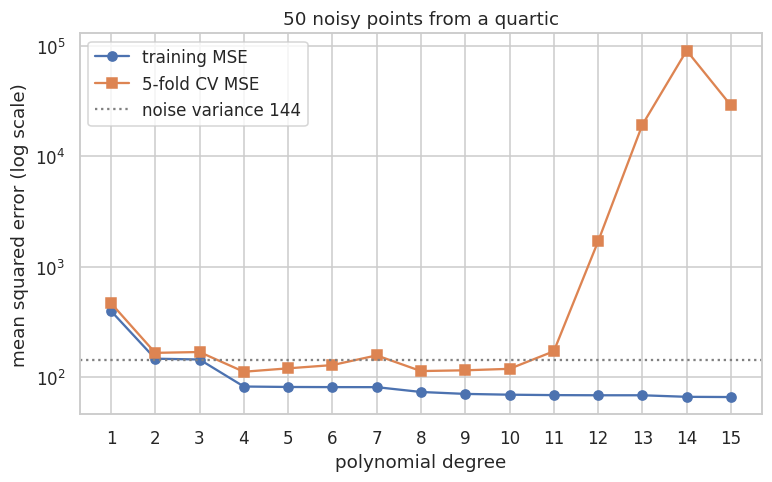

        train_mse      cv_mse         gap      ratio
degree                                              
1        397.8800    468.4700     70.6000     1.1800
2        146.8600    165.9000     19.0400     1.1300
3        144.4100    168.8300     24.4200     1.1700
4         82.1600    111.8500     29.6900     1.3600
5         81.3900    120.0800     38.6900     1.4800
6         81.1400    128.5300     47.3900     1.5800
7         81.0700    157.3500     76.2700     1.9400
8         73.3200    113.4500     40.1300     1.5500
9         70.4200    115.2500     44.8400     1.6400
10        69.2800    118.8700     49.5900     1.7200
11        68.6700    171.4900    102.8200     2.5000
12        68.4400  1,699.0900  1,630.6500    24.8200
13        68.4400 19,405.7200 19,337.2800   283.5500
14        66.2600 91,266.7500 91,200.4900 1,377.3200
15        65.9500 28,992.7500 28,926.8000   439.6200

(b) training MSE at higher degree (Chebyshev basis, which stays numerically stable longer):
    de

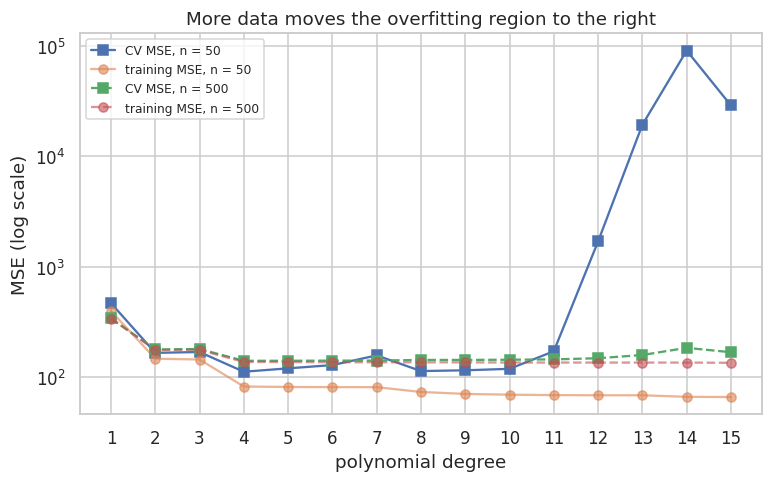

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(_sweep.index, _sweep["train_mse"], marker="o", label="training MSE")
ax.plot(_sweep.index, _sweep["cv_mse"], marker="s", label="5-fold CV MSE")
ax.axhline(12.0 ** 2, color="grey", linestyle=":", label="noise variance 144")
ax.set_yscale("log")
ax.set_xlabel("polynomial degree")
ax.set_ylabel("mean squared error (log scale)")
ax.set_title("50 noisy points from a quartic")
ax.set_xticks(range(1, 16))
ax.legend()
plt.show()
_sweep_gap = _sweep.assign(gap=_sweep["cv_mse"] - _sweep["train_mse"], ratio=_sweep["cv_mse"] / _sweep["train_mse"])
print(_sweep_gap.round(2).to_string())

# (b) beyond degree 15: towards interpolation
from numpy.polynomial import Chebyshev
from scipy.interpolate import BarycentricInterpolator
print("\n(b) training MSE at higher degree (Chebyshev basis, which stays numerically stable longer):")
for d in (20, 30, 40):
    fit = Chebyshev.fit(_x_poly, _y_poly, d)
    print(f"    degree {d}: training MSE {np.mean((fit(_x_poly) - _y_poly) ** 2):.2f}")
_interp = BarycentricInterpolator(_x_poly, _y_poly, rng=SEED)  # the degree-49 polynomial through all 50 points
print(f"    degree 49 (exact interpolation): training MSE {np.mean((_interp(_x_poly) - _y_poly) ** 2):.2e}")
_val_med = []
for tr, va in KFold(5, shuffle=True, random_state=SEED).split(_x_poly):
    f = BarycentricInterpolator(_x_poly[tr], _y_poly[tr], rng=SEED)   # degree 39 through 40 points
    with np.errstate(over="ignore", invalid="ignore"):   # a few predictions overflow; the median is unaffected
        _val_med.append(np.median(np.abs(f(_x_poly[va]) - _y_poly[va])))
print("    degree 39 through each fold's 40 training points: median absolute validation error by fold",
      [f"{e:.1e}" for e in _val_med], "(the noise sd is 12)")

# (c) ten times more data, same noise
_poly_rng_500 = np.random.default_rng(SEED)
_x_500 = _poly_rng_500.uniform(-3, 3, 500)
_y_500 = (_x_500 ** 4 - 3 * _x_500 ** 2 + _x_500 + 5) + _poly_rng_500.normal(0, 12.0, 500)
_sweep_500 = degree_sweep(_x_500, _y_500, range(1, 16), KFold(5, shuffle=True, random_state=SEED))
print("\n(c) 500 points:")
print(_sweep_500.assign(gap=_sweep_500["cv_mse"] - _sweep_500["train_mse"]).round(2).to_string())
for name, sw in (("50 points ", _sweep), ("500 points", _sweep_500)):
    best = sw["cv_mse"].idxmin()
    within5 = sw.index[sw["cv_mse"] <= 1.05 * sw["cv_mse"].min()].tolist()
    print(f"{name}: best degree {best}, CV MSE {sw['cv_mse'].min():.1f}; degrees within 5 % of the best {within5}; "
          f"degree 15 / best = {sw.loc[15, 'cv_mse'] / sw['cv_mse'].min():.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, sw, style in (("n = 50", _sweep, "-"), ("n = 500", _sweep_500, "--")):
    ax.plot(sw.index, sw["cv_mse"], linestyle=style, marker="s", label=f"CV MSE, {name}")
    ax.plot(sw.index, sw["train_mse"], linestyle=style, marker="o", alpha=0.6, label=f"training MSE, {name}")
ax.set_yscale("log")
ax.set_xlabel("polynomial degree")
ax.set_ylabel("MSE (log scale)")
ax.set_xticks(range(1, 16))
ax.set_title("More data moves the overfitting region to the right")
ax.legend(fontsize=8)
plt.show()

**Your answer:**

**(a)** На графіку з логарифмічною віссю видно дві області. **Недонавчання** охоплює степені 1–3: і навчальна, і перехресна помилки великі (397,9 і 468,5 при степені 1; 144,4 і 168,8 при степені 3) і близькі між собою (відношення CV/train 1,13–1,18). Модель просто не здатна описати форму кривої четвертого степеня, і помилка є зміщенням. Найкращий степінь 4 (train 82,2, CV 111,9). **Перенавчання** починається зі степеня 5: навчальна помилка й далі повільно спадає (81,4 → 65,9 до степеня 15), а перехресна зростає (120,1; 128,5; 157,4), після шумної ділянки 8–10 (113–119) вибухає: 171,5 при 11, 1 699 при 12, 19 406 при 13, 91 267 при 14. Відношення CV/train зростає від 1,36 у найкращій точці до 2,5 при степені 11 і до сотень далі. Діагностикою є саме розрив, бо кожна крива окремо неінформативна: навчальна помилка спадає завжди (модель степеня d може все, що може модель степеня d − 1), а висока перехресна помилка сама по собі не каже, чи модель занадто проста, чи занадто гнучка. Малий розрив при великій помилці означає недонавчання, а розрив, що зростає, означає перенавчання. Пунктирна лінія 144 на графіку позначає дисперсію шуму; у цій вибірці з 50 точок шум випадково менший, тому найкраща модель лежить нижче за неї.

**(b)** Коли степінь наближається до n − 1 = 49, навчальна MSE прямує до нуля, бо поліном степеня n − 1 має n коефіцієнтів і може пройти точно через n точок з різними x (інтерполяція Лагранжа). Я перевірив це в базисі Чебишова, який довше лишається чисельно стійким: навчальна MSE 57,62 при степені 20, 45,36 при 30, 25,63 при 40 і 0,00 для точного інтерполянта степеня 49. Конвеєр `PolynomialFeatures` + `LinearRegression` стає чисельно погано обумовленим раніше (ознака x¹⁵ сягає 3¹⁵ ≈ 1,4·10⁷), тому при степенях 12–13 його навчальна помилка застигає на 68,44. Валідаційна помилка при цьому вибухає. Поліном степеня 39, проведений точно через 40 навчальних точок кожного фолду, на валідаційних точках помиляється в типовому випадку (медіана абсолютної помилки) на 4·10⁵–3·10⁹ залежно від фолду, тоді як стандартне відхилення шуму дорівнює 12, а окремі прогнози настільки великі, що виходять за межі чисел із рухомою комою. Між вузлами і біля країв такий поліном дико коливається.

**(c)** З 500 точками і тим самим шумом найкращим знову є степінь 4 (CV 140,50), але тепер усі степені від 4 до 11 лежать у межах 5 % від найкращого (140,5–144,8), перехресна помилка помітно зростає лише з 12–13 (148,3 і 158,6), а степінь 15 гірший за найкращий лише в 1,20 раза проти 259 разів при 50 точках. Розрив між кривими при степені 4 зменшився з 29,7 до 3,2, а навчальна MSE (137,3) наблизилася до дисперсії шуму 144. Отже, область перенавчання зсунулася приблизно з 5 до 12 і стала значно пологішою. Загальна залежність: що більше даних, то складнішу модель можна собі дозволити, бо дисперсія оцінки моделі з p параметрами зростає приблизно як p/n; на малих вибірках слід обирати простіші моделі.

## 7. Task 6 — Tune a tree honestly

Applied.

*see Practice 3 §8.3 and §6.4*

In [17]:
def tune_tree(X, y, cv, depths=(1, 2, 3, 4, 5, 6, 8, 10, None), criteria=("gini", "entropy")):
    """Grid-search a DecisionTreeClassifier over max_depth and criterion.

    Use GridSearchCV with the given `cv`, scoring='accuracy', refit=True,
    and DecisionTreeClassifier(random_state=SEED).

    Return a dict with exactly these four keys:
        'best_depth'      the chosen max_depth (may be None)
        'best_criterion'  the chosen criterion, a string
        'best_cv_score'   the best cross-validated accuracy, a float
        'search'          the fitted GridSearchCV object
    """
    search = GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        param_grid={"max_depth": list(depths), "criterion": list(criteria)},
        cv=cv, scoring="accuracy", refit=True,
    )
    search.fit(X, y)
    return {
        "best_depth": search.best_params_["max_depth"],
        "best_criterion": search.best_params_["criterion"],
        "best_cv_score": float(search.best_score_),
        "search": search,
    }

In [18]:
_X_iris = iris.drop(columns=["Id", "Species"]).values
_y_iris = iris["Species"].values
_iris_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

_tuned = tune_tree(_X_iris, _y_iris, _iris_cv)

assert set(_tuned) == {"best_depth", "best_criterion", "best_cv_score", "search"}
assert _tuned["best_criterion"] in ("gini", "entropy")
assert 0.9 < _tuned["best_cv_score"] <= 1.0, f"CV score looks wrong: {_tuned['best_cv_score']}"
assert len(_tuned["search"].cv_results_["params"]) == 18, \
    "9 depths x 2 criteria = 18 combinations"

# A depth-1 tree cannot separate three classes: it has only two leaves.
_depth1 = cross_val_score(DecisionTreeClassifier(max_depth=1, random_state=SEED),
                          _X_iris, _y_iris, cv=_iris_cv).mean()
assert _depth1 < 0.75, f"a two-leaf tree should not classify three classes well, got {_depth1:.4f}"
assert _tuned["best_cv_score"] > _depth1, "tuning should beat the depth-1 stump"

# The chosen tree must not be the fully grown one if a shallower one ties it.
_full = cross_val_score(DecisionTreeClassifier(random_state=SEED), _X_iris, _y_iris, cv=_iris_cv).mean()
print(f"best: max_depth={_tuned['best_depth']}, criterion={_tuned['best_criterion']}, "
      f"CV {_tuned['best_cv_score']:.4f}")
print(f"depth-1 stump CV {_depth1:.4f}   fully grown tree CV {_full:.4f}")
print("Task 6 passed.")

best: max_depth=4, criterion=gini, CV 0.9333
depth-1 stump CV 0.6667   fully grown tree CV 0.9333
Task 6 passed.


### Question 4 — tree hyperparameters

**(a)** Using `_tuned['search'].cv_results_`, tabulate the CV score at
every `max_depth` for both criteria. **Which direction is underfitting
and which is overfitting?** Give the depth at which each begins for this
data.

**(b)** `gini` and `criterion='entropy'` gave nearly the same answer.
Explain what each measures and why they rarely disagree. Construct or
describe a situation in which they might.

**(c)** Fit a tree with `max_depth=None` and report its **training**
accuracy. Explain in one sentence why that number is uninformative, and
name the other hyperparameter from Practice 3 §8.3 that limits the same
behaviour from a different direction.

In [19]:
# (a) the whole grid
_cvr = pd.DataFrame(_tuned["search"].cv_results_)
_cvr["depth"] = _cvr["param_max_depth"].apply(lambda d: "None" if d is None else str(d))
_grid = _cvr.pivot(index="depth", columns="param_criterion", values="mean_test_score")
_grid = _grid.loc[["1", "2", "3", "4", "5", "6", "8", "10", "None"]]
_grid["sd (gini)"] = _cvr[_cvr["param_criterion"] == "gini"].set_index("depth")["std_test_score"]
_train_acc, _leaves = {}, {}
for d in (1, 2, 3, 4, 5, 6, 8, 10, None):
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(_X_iris, _y_iris)
    _train_acc["None" if d is None else str(d)] = t.score(_X_iris, _y_iris)
    _leaves["None" if d is None else str(d)] = t.get_n_leaves()
_grid["train (gini)"] = pd.Series(_train_acc)
_grid["leaves (gini)"] = pd.Series(_leaves)
print(_grid.round(4).to_string())

# (b) can gini and entropy prefer different splits of the same node?
def _gini(c):
    p = np.asarray(c, float) / np.sum(c)
    return 1 - np.sum(p ** 2)

def _entropy(c):
    p = np.asarray(c, float) / np.sum(c)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def _gain(f, parent, left):
    right = np.asarray(parent) - np.asarray(left)
    n = np.sum(parent)
    return f(parent) - np.sum(left) / n * f(left) - np.sum(right) / n * f(right)

_parent = np.array([40, 40, 20])
_candidates = [np.array([a, b, c]) for a in range(0, 41, 5) for b in range(0, 41, 5) for c in range(0, 21, 5)
               if 0 < a + b + c < 100]
_found = None
for i, s1 in enumerate(_candidates):
    for s2 in _candidates[i + 1:]:
        g = _gain(_gini, _parent, s1) - _gain(_gini, _parent, s2)
        e = _gain(_entropy, _parent, s1) - _gain(_entropy, _parent, s2)
        if g > 0.01 and e < -0.01:
            _found = (s1, s2)
            break
    if _found:
        break
_s1, _s2 = _found
print(f"\n(b) parent node with class counts {_parent.tolist()}")
for name, s in (("split A", _s1), ("split B", _s2)):
    print(f"    {name}: left {s.tolist()}  right {(_parent - s).tolist()}   "
          f"gini gain {_gain(_gini, _parent, s):.4f}   entropy gain {_gain(_entropy, _parent, s):.4f}")

# (c) a fully grown tree, scored on the rows it was grown on
_grown = DecisionTreeClassifier(max_depth=None, random_state=SEED).fit(_X_iris, _y_iris)
print(f"\n(c) max_depth=None: training accuracy {_grown.score(_X_iris, _y_iris):.4f}, "
      f"{_grown.get_n_leaves()} leaves, depth {_grown.get_depth()}, CV accuracy {_full:.4f}")
for leaf in (1, 5, 10):
    t = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=SEED)
    print(f"    min_samples_leaf = {leaf:2}: leaves {t.fit(_X_iris, _y_iris).get_n_leaves():2}, "
          f"train {t.score(_X_iris, _y_iris):.4f}, CV {cross_val_score(t, _X_iris, _y_iris, cv=_iris_cv).mean():.4f}")

param_criterion  entropy   gini  sd (gini)  train (gini)  leaves (gini)
depth                                                                  
1                 0.6667 0.6667     0.0000        0.6667              2
2                 0.9200 0.9200     0.0452        0.9600              3
3                 0.9200 0.9200     0.0452        0.9733              5
4                 0.9333 0.9333     0.0471        0.9933              8
5                 0.9333 0.9333     0.0471        1.0000              9
6                 0.9333 0.9333     0.0471        1.0000              9
8                 0.9333 0.9333     0.0471        1.0000              9
10                0.9333 0.9333     0.0471        1.0000              9
None              0.9333 0.9333     0.0471        1.0000              9

(b) parent node with class counts [40, 40, 20]
    split A: left [0, 0, 5]  right [40, 40, 15]   gini gain 0.0505   entropy gain 0.1241
    split B: left [15, 20, 0]  right [25, 20, 20]   gini gain 0.0378   

**Your answer:**

**(a)** Перехресна точність за `cv_results_`:

| max_depth | gini | entropy | train (gini) | листків |
|---|---|---|---|---|
| 1 | 0,6667 | 0,6667 | 0,6667 | 2 |
| 2 | 0,9200 | 0,9200 | 0,9600 | 3 |
| 3 | 0,9200 | 0,9200 | 0,9733 | 5 |
| 4 | 0,9333 | 0,9333 | 0,9933 | 8 |
| 5–None | 0,9333 | 0,9333 | 1,0000 | 9 |

Мала глибина означає **недонавчання**. Пень глибини 1 має два листки і не може розділити три класи (0,6667 і на навчанні, і на перевірці), глибини 2–3 ще трохи недотягують (0,92). Недонавчання закінчується на глибині 4, яку й обрав пошук як найменшу з однаково найкращих. Велика глибина означає **перенавчання**, і починається воно з глибини 5: дерево досягає 100 % навчальної точності (9 листків, фактична глибина 5), а перехресна лишається 0,9333, тобто розрив 0,067, і додатковий листок обслуговує одну-дві навчальні точки. На такому малому і простому наборі перехресна точність не падає, бо дерево зупиняється, щойно листки стають чистими, тож перенавчання проявляється як розрив між навчальною і перехресною точністю, а не як падіння останньої.

**(b)** Gini = 1 − Σpᵢ² є ймовірністю того, що два випадково взяті з вузла об'єкти належать до різних класів. Ентропія −Σpᵢ log₂ pᵢ є кількістю інформації (у бітах), потрібною, щоб закодувати клас об'єкта з вузла. Обидві міри нульові для чистого вузла, максимальні для рівномірного змішування і мають дуже схожу увігнуту форму, тому впорядковують кандидатні розбиття майже однаково, а дереву важливий лише порядок. Розбіжність я сконструював перебором для вузла з класами [40, 40, 20]. Розбиття A відокремлює чисту групу з 5 об'єктів третього класу (ліворуч [0, 0, 5], праворуч [40, 40, 15]). Розбиття B дає ліворуч [15, 20, 0], праворуч [25, 20, 20]. Приріст gini у A 0,0505, у B 0,0378, тому gini обирає A; приріст ентропії у A 0,1241, у B 0,1523, тому ентропія обирає B. Ентропія чутливіша до малих частот (функція −p log p дуже крута біля нуля), тож повне зникнення третього класу з лівої частини в B дає їй великий виграш, тоді як gini, що працює з квадратами частот, більше цінує одну цілком чисту, хоч і малу, гілку. Такі розбіжності можливі у вузлах з кількома класами і кандидатами різного характеру, але рідко змінюють підсумкову точність.

**(c)** Дерево з `max_depth=None` має навчальну точність 1,0000 (9 листків, глибина 5) при перехресній 0,9333. Це число неінформативне, бо дерево, вирощене до чистоти, за побудовою відтворює мітки тих самих рядків, на яких виросло, і 100 % означає лише, що в Iris немає двох однакових рядків з різними мітками. Той самий ефект з іншого боку обмежує `min_samples_leaf` (Practice 3 §8.3), який забороняє листки, що спираються на менш ніж n об'єктів: при 5 дерево має 6 листків, навчальну точність 0,9733 і перехресну 0,92, при 10 відповідно 6 листків, 0,9600 і 0,92.

## 8. Task 7 — Choose k without touching the test set

Applied. This is the procedure from Practice 3 §10.4, implemented.

*see Practice 3 §10.3 and §10.4*

In [20]:
def honest_k_selection(X_train, y_train, X_test, y_test, k_values, cv):
    """Choose k by cross-validation on the training set, then measure once.

    For each k in `k_values`, cross-validate
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    on the TRAINING data only, using `cv`.

    Choose the k with the highest mean CV accuracy (the smallest such k if
    several tie). Refit that pipeline on all the training data and score
    it once on the test set.

    Also record, for comparison, the k that would have been chosen by
    scoring each k directly on the TEST set, and that k's test score.

    Return a dict with exactly these five keys:
        'cv_scores'         a 1-D array of mean CV accuracy, one per k
        'best_k_cv'         the k chosen by cross-validation
        'test_accuracy'     the honest test accuracy of that k
        'best_k_peeking'    the k that maximises test accuracy
        'peeking_accuracy'  that k's test accuracy (an optimistic number)
    """
    k_list = list(k_values)

    def pipeline(k):
        return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

    cv_scores = np.array([
        cross_val_score(pipeline(k), X_train, y_train, cv=cv, scoring="accuracy").mean()
        for k in k_list
    ])
    best_k_cv = k_list[int(np.argmax(cv_scores))]          # argmax returns the first, i.e. smallest, k on a tie
    test_accuracy = pipeline(best_k_cv).fit(X_train, y_train).score(X_test, y_test)

    # The procedure NOT to use, recorded only for comparison.
    test_scores = np.array([pipeline(k).fit(X_train, y_train).score(X_test, y_test) for k in k_list])
    best_k_peeking = k_list[int(np.argmax(test_scores))]

    return {
        "cv_scores": cv_scores,
        "best_k_cv": best_k_cv,
        "test_accuracy": float(test_accuracy),
        "best_k_peeking": best_k_peeking,
        "peeking_accuracy": float(test_scores.max()),
    }

In [21]:
_t = titanic.copy()
_t["Age"] = _t["Age"].fillna(_t.groupby(["Pclass", "Sex"])["Age"].transform("median"))
_t["Sex"] = (_t["Sex"] == "female").astype(int)
_X_knn = _t[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]].values
_y_knn = _t["Survived"].values

_Xk_tr, _Xk_te, _yk_tr, _yk_te = train_test_split(
    _X_knn, _y_knn, test_size=0.25, random_state=SEED, stratify=_y_knn
)
_k_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
_sel = honest_k_selection(_Xk_tr, _yk_tr, _Xk_te, _yk_te, range(1, 31), _k_cv)

assert set(_sel) == {"cv_scores", "best_k_cv", "test_accuracy",
                     "best_k_peeking", "peeking_accuracy"}
assert len(_sel["cv_scores"]) == 30
assert 1 <= _sel["best_k_cv"] <= 30

# The k chosen by CV must be the argmax OF THE CV SCORES, not of the test scores.
assert _sel["best_k_cv"] == list(range(1, 31))[int(np.argmax(_sel["cv_scores"]))], \
    "best_k_cv must maximise the cross-validated score, not the test score"

# Peeking at the test set can never look worse than the honest procedure:
# it is the maximum over the same set of numbers.
assert _sel["peeking_accuracy"] >= _sel["test_accuracy"] - 1e-12, \
    "selecting on the test set cannot produce a lower test score than any single choice"

print(f"k by cross-validation : {_sel['best_k_cv']:2}  ->  honest test accuracy "
      f"{_sel['test_accuracy']:.4f}")
print(f"k by peeking at test  : {_sel['best_k_peeking']:2}  ->  optimistic accuracy "
      f"{_sel['peeking_accuracy']:.4f}")
print(f"the optimism is {_sel['peeking_accuracy'] - _sel['test_accuracy']:+.4f}")
print("Task 7 passed.")

k by cross-validation : 18  ->  honest test accuracy 0.8206
k by peeking at test  : 25  ->  optimistic accuracy 0.8520
the optimism is +0.0314
Task 7 passed.


### Question 5 — k, and the one-use rule

**(a)** Plot your `cv_scores` against k. **Which end is underfitting and
which is overfitting?** Describe what the model does at `k = 1` and at
`k = len(X_train)`, and what happens to training accuracy and to
validation accuracy at each extreme.

**(b)** Your two procedures reported different numbers. Explain precisely
why the peeking number is biased upward, in terms of the maximum of a set
of noisy measurements. Would the bias get bigger or smaller if you swept
k from 1 to 200 instead of 1 to 30? Test it.

**(c)** Vary `test_size` over 0.1, 0.25 and 0.4 with the same seed, and
report the honest test accuracy at each. Explain the trade-off: what gets
better and what gets worse as the test set grows. Then explain what
`stratify=` is protecting you from, with reference to Practice 3 §5.3.

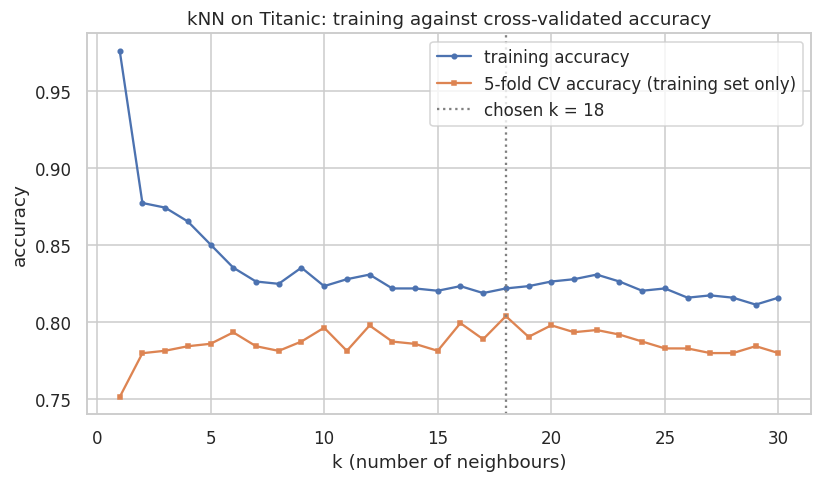

CV accuracy at k = 1, 5, 10, 20, 30: [0.7515 0.786  0.7964 0.798  0.78  ] ; maximum 0.8039 at k = 18
training accuracy at k = 1, 5, 18, 30: [0.976  0.8503 0.8219 0.8159]
k = 668 (all training rows): training accuracy 0.6168, distinct predictions [0], training share of class 0 0.6168
k = 534 (every row of a CV training fold): CV accuracy 0.6168
k = 1: training accuracy 0.9760 (not exactly 1 because 132 training rows share their features with another row)



one split, k in 1..200: CV picks k = 18 -> 0.8206; peeking picks k = 25 -> 0.8520; optimism +0.0314


10 splits, k in 1.. 30: mean optimism +0.0206, min +0.0000, max +0.0448  (4.6 test passengers)
10 splits, k in 1..200: mean optimism +0.0211, min +0.0000, max +0.0448  (4.7 test passengers)
optimism per split, 1..30 : [0.0179 0.0135 0.0135 0.0314 0.     0.0359 0.0179 0.0448 0.0045 0.0269]
optimism per split, 1..200: [0.0179 0.0135 0.0135 0.0314 0.     0.0359 0.0179 0.0448 0.0045 0.0314]

(c) test_size, same seed


    test_size  0.1: train 801  test  90  chosen k 18  honest test accuracy 0.8333 +/- 0.0393 (one standard error)


    test_size 0.25: train 668  test 223  chosen k 18  honest test accuracy 0.8206 +/- 0.0257 (one standard error)


    test_size  0.4: train 534  test 357  chosen k  8  honest test accuracy 0.8095 +/- 0.0208 (one standard error)
    test_size 0.1, 200 seeds, without stratify: survival rate in the test set 0.2444 .. 0.5000 (sd 0.0499); full data 0.3838
    test_size 0.1, 200 seeds, with stratify   : survival rate in the test set 0.3889 .. 0.3889 (sd 0.0000); full data 0.3838


In [22]:
# (a) the CV curve, with training accuracy for contrast
_ks = np.arange(1, 31)
_train_curve = [make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(_Xk_tr, _yk_tr)
                .score(_Xk_tr, _yk_tr) for k in _ks]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(_ks, _train_curve, marker="o", markersize=3, label="training accuracy")
ax.plot(_ks, _sel["cv_scores"], marker="s", markersize=3, label="5-fold CV accuracy (training set only)")
ax.axvline(_sel["best_k_cv"], color="grey", linestyle=":", label=f"chosen k = {_sel['best_k_cv']}")
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("accuracy")
ax.set_title("kNN on Titanic: training against cross-validated accuracy")
ax.legend()
plt.show()
print("CV accuracy at k = 1, 5, 10, 20, 30:", _sel["cv_scores"][[0, 4, 9, 19, 29]].round(4),
      f"; maximum {_sel['cv_scores'].max():.4f} at k = {_sel['best_k_cv']}")
print("training accuracy at k = 1, 5, 18, 30:", np.array(_train_curve)[[0, 4, 17, 29]].round(4))

_n_train = len(_yk_tr)
_everyone = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=_n_train)).fit(_Xk_tr, _yk_tr)
print(f"k = {_n_train} (all training rows): training accuracy {_everyone.score(_Xk_tr, _yk_tr):.4f}, "
      f"distinct predictions {np.unique(_everyone.predict(_Xk_tr)).tolist()}, "
      f"training share of class 0 {np.mean(_yk_tr == 0):.4f}")
_largest_k = int(_n_train * 4 / 5)            # the most a 5-fold training fold allows
_cv_largest = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=_largest_k)),
                              _Xk_tr, _yk_tr, cv=_k_cv).mean()
print(f"k = {_largest_k} (every row of a CV training fold): CV accuracy {_cv_largest:.4f}")
_one = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)).fit(_Xk_tr, _yk_tr)
_dup = pd.DataFrame(_Xk_tr).duplicated(keep=False).sum()
print(f"k = 1: training accuracy {_one.score(_Xk_tr, _yk_tr):.4f} "
      f"(not exactly 1 because {_dup} training rows share their features with another row)")

# (b) the optimism of peeking, 1..30 against 1..200, one split and then 20 splits
_one_split_200 = honest_k_selection(_Xk_tr, _yk_tr, _Xk_te, _yk_te, range(1, 201), _k_cv)
print(f"\none split, k in 1..200: CV picks k = {_one_split_200['best_k_cv']} -> {_one_split_200['test_accuracy']:.4f}; "
      f"peeking picks k = {_one_split_200['best_k_peeking']} -> {_one_split_200['peeking_accuracy']:.4f}; "
      f"optimism {_one_split_200['peeking_accuracy'] - _one_split_200['test_accuracy']:+.4f}")
def _accuracy_by_k(X_tr, y_tr, X_te, y_te, k_values, cv):
    """Mean CV accuracy and test accuracy of StandardScaler -> kNN for every k.

    The same arithmetic as honest_k_selection, but each fold is scaled once
    rather than once per k, which keeps a long sweep over many splits fast.
    """
    folds = []
    for tr, va in cv.split(X_tr, y_tr):
        scaler = StandardScaler().fit(X_tr[tr])
        folds.append((scaler.transform(X_tr[tr]), y_tr[tr], scaler.transform(X_tr[va]), y_tr[va]))
    scaler = StandardScaler().fit(X_tr)
    X_fit, X_eval = scaler.transform(X_tr), scaler.transform(X_te)
    cv_mean = np.array([np.mean([KNeighborsClassifier(n_neighbors=k).fit(a, b).score(c, d)
                                 for a, b, c, d in folds]) for k in k_values])
    test = np.array([KNeighborsClassifier(n_neighbors=k).fit(X_fit, y_tr).score(X_eval, y_te) for k in k_values])
    return cv_mean, test

# It must reproduce honest_k_selection exactly before it is trusted.
_cv_check, _test_check = _accuracy_by_k(_Xk_tr, _yk_tr, _Xk_te, _yk_te, range(1, 31), _k_cv)
assert np.array_equal(_cv_check, _sel["cv_scores"])
assert _test_check[_sel["best_k_cv"] - 1] == _sel["test_accuracy"] and _test_check.max() == _sel["peeking_accuracy"]

_n_splits_rep = 10
_opt = {30: [], 200: []}
for split_seed in range(_n_splits_rep):
    a_tr, a_te, b_tr, b_te = train_test_split(_X_knn, _y_knn, test_size=0.25,
                                              random_state=split_seed, stratify=_y_knn)
    cv_mean, test = _accuracy_by_k(a_tr, b_tr, a_te, b_te, range(1, 201),
                                   StratifiedKFold(5, shuffle=True, random_state=split_seed))
    for top in (30, 200):
        honest = test[int(np.argmax(cv_mean[:top]))]          # k chosen by CV within 1..top
        _opt[top].append(test[:top].max() - honest)            # peeking minus honest
for top, values in _opt.items():
    values = np.array(values)
    print(f"{_n_splits_rep} splits, k in 1..{top:3}: mean optimism {values.mean():+.4f}, min {values.min():+.4f}, "
          f"max {values.max():+.4f}  ({values.mean() * len(_yk_te):.1f} test passengers)")
print("optimism per split, 1..30 :", np.round(_opt[30], 4))
print("optimism per split, 1..200:", np.round(_opt[200], 4))

# (c) the size of the test set
print("\n(c) test_size, same seed")
for ts in (0.1, 0.25, 0.4):
    a_tr, a_te, b_tr, b_te = train_test_split(_X_knn, _y_knn, test_size=ts, random_state=SEED, stratify=_y_knn)
    r = honest_k_selection(a_tr, b_tr, a_te, b_te, range(1, 31), _k_cv)
    se = np.sqrt(r["test_accuracy"] * (1 - r["test_accuracy"]) / len(b_te))
    print(f"    test_size {ts:4}: train {len(b_tr):3}  test {len(b_te):3}  chosen k {r['best_k_cv']:2}  "
          f"honest test accuracy {r['test_accuracy']:.4f} +/- {se:.4f} (one standard error)")

for label, kwargs in (("without stratify", {}), ("with stratify", {"stratify": _y_knn})):
    rates = [train_test_split(_X_knn, _y_knn, test_size=0.1, random_state=s, **kwargs)[3].mean()
             for s in range(200)]
    print(f"    test_size 0.1, 200 seeds, {label:16}: survival rate in the test set "
          f"{min(rates):.4f} .. {max(rates):.4f} (sd {np.std(rates):.4f}); full data {_y_knn.mean():.4f}")

**Your answer:**

**(a)** Перехресна точність при k = 1 найнижча (0,7515), швидко зростає до 0,78–0,80 при k ≈ 2–20, досягає максимуму 0,8039 при k = 18 і повільно спадає до 0,78 при k = 30. Малий k означає **перенавчання**, великий означає **недонавчання**. При k = 1 кожна навчальна точка є власним найближчим сусідом, тому навчальна точність майже ідеальна (0,9760, не 1 лише тому, що 132 навчальні рядки мають однакові ознаки з іншими рядками, іноді з іншою міткою), а перехресна найгірша (0,7515): модель запам'ятовує кожного пасажира разом із шумом. Зі зростанням k навчальна точність падає (0,8503 при k = 5, 0,8219 при k = 18, 0,8159 при k = 30), а перехресна спершу зростає, бо голосування згладжує шум. При k = `len(X_train)` = 668 кожен прогноз є голосуванням усіх навчальних пасажирів, тож модель завжди прогнозує клас 0 («загинув»): навчальна точність 0,6168 дорівнює частці цього класу, а перехресна при найбільшому можливому k = 534 теж 0,6168, тобто рівень базової моделі. На цьому краї обидві точності падають до бази, і це чисте зміщення.

**(b)** Перехресна перевірка обрала k = 18 з чесною тестовою точністю 0,8206, а вибір за тестом дав k = 25 і 0,8520, тобто оптимізм +0,0314 (7 з 223 пасажирів). Тестова точність кожного k є шумним вимірюванням: справжня точність плюс випадкова похибка зі стандартним відхиленням близько 0,026 на 223 пасажирах. Обираючи k з найбільшим тестовим результатом, ми обираємо той k, чия похибка випадково виявилася найбільш додатною, а математичне сподівання максимуму шумних величин більше за максимум їхніх сподівань. Тому число 0,8520 є максимумом із 30 шумних вимірювань, а не оцінкою точності якоїсь моделі. Для діапазону 1–200 на цьому розбитті нічого не змінилося (знову k = 25 і 0,8520), тому я повторив обидві процедури на 10 різних розбиттях: середній оптимізм +0,0206 для 1–30 і +0,0211 для 1–200, максимум 0,0448 в обох випадках, а розширений діапазон змінив результат лише в одному розбитті з десяти (з 0,0269 до 0,0314). Зміщення зростає, але дуже мало, бо додані k від 31 до 200 дають дуже згладжені, сильно корельовані між собою і загалом слабші моделі, які рідко перевершують найкращу з перших тридцяти. Зміщення зростає з кількістю фактично різних кандидатів, а не з їхньою номінальною кількістю.

**(c)** При тому самому seed отримано: `test_size` 0,1 дає 801 навчальний і 90 тестових рядків, k = 18 і тестову точність 0,8333 ± 0,0393 (одна стандартна похибка); 0,25 дає 668 і 223 рядки, k = 18 і 0,8206 ± 0,0257; 0,4 дає 534 і 357 рядків, k = 8 і 0,8095 ± 0,0208. Більший тест робить оцінку точнішою (похибка зменшується з 0,039 до 0,021), але залишає менше даних для навчання і вибору k, тож модель трохи гірша, а вибір k менш стабільний (при 0,4 вибрано k = 8). Менший тест дає кращу модель, але її оцінка 0,83 ± 0,04 сумісна з будь-яким значенням від 0,79 до 0,87. Різниці між трьома точностями лежать у межах їхніх похибок, тож не доводять, що більший навчальний набір допоміг. `stratify=` захищає від того, що випадкове розбиття змінить частку класів у тесті. Без стратифікації при `test_size=0.1` на 200 seed частка тих, хто вижив, у тесті коливалася від 0,2444 до 0,5000 (sd 0,0499), зі стратифікацією вона завжди 0,3889 (у повних даних 0,3838). Як і в Practice 3 §5.3, без стратифікації тестова точність змінюється разом із базовим рівнем, незалежно від моделі, і це додаткове джерело шуму особливо відчутне на малих тестових наборах і для малих класів.

## 9. Task 8 — Recover an SVM boundary in original units

Applied. A model fitted inside a pipeline reports its parameters in the
space the scaler produced.

*see Practice 3 §11.4*

In [23]:
def boundary_in_original_units(pipeline):
    """Convert a fitted (StandardScaler -> linear SVC) pipeline's decision
    boundary from scaled space back to original coordinates.

    The pipeline has exactly two steps: 'standardscaler' and 'svc', and
    the SVC has kernel='linear' and was fitted on two features.

    In scaled space the boundary is  w1*z1 + w2*z2 + b = 0, with
    z1 = (x - mu_x)/s_x and z2 = (y - mu_y)/s_y.

    Solve for y and return a tuple (slope, intercept) such that
    y = slope * x + intercept is that same boundary in original units.

    Raise ValueError if w2 is zero (a vertical boundary has no such form).
    """
    scaler = pipeline.named_steps["standardscaler"]
    svc = pipeline.named_steps["svc"]
    w1, w2 = svc.coef_[0]
    b = svc.intercept_[0]
    mu_x, mu_y = scaler.mean_
    s_x, s_y = scaler.scale_
    if w2 == 0:
        raise ValueError("w2 is zero: the boundary is vertical and has no form y = slope * x + intercept")
    # w1 (x - mu_x)/s_x + w2 (y - mu_y)/s_y + b = 0  ->  y = mu_y - (s_y / w2) * (w1 (x - mu_x)/s_x + b)
    slope = -(w1 * s_y) / (w2 * s_x)
    intercept = mu_y + (s_y / w2) * (w1 * mu_x / s_x - b)
    return float(slope), float(intercept)

In [24]:
_svr_rng = np.random.default_rng(SEED)
_n = 300
_x_lines = _svr_rng.uniform(0, 5, _n)
_y1 = 1.0 * _x_lines + 3.0 + _svr_rng.normal(0, 1, _n)
_y2 = 2.0 * _x_lines + 5.0 + _svr_rng.normal(0, 1, _n)

_X_two = np.vstack([np.column_stack([_x_lines, _y1]), np.column_stack([_x_lines, _y2])])
_y_two = np.hstack([np.zeros(_n, dtype=int), np.ones(_n, dtype=int)])

_pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, random_state=SEED))
_pipe.fit(_X_two, _y_two)

_slope, _intercept = boundary_in_original_units(_pipe)

# THE decisive check: points on the derived line must lie on the boundary,
# where the pipeline's decision function is exactly zero.
_check_x = np.linspace(0.5, 4.5, 9)
_check_y = _slope * _check_x + _intercept
_decisions = _pipe.decision_function(np.column_stack([_check_x, _check_y]))
assert np.allclose(_decisions, 0.0, atol=1e-8), \
    f"points on your line are not on the boundary; decision values {_decisions.round(6)}"

# The boundary must lie between the two generating lines.
assert 1.0 < _slope < 2.0, f"slope {_slope:.4f} should be between the true slopes 1 and 2"

# Points clearly above and below must fall on opposite sides.
assert _pipe.predict([[2.5, _slope * 2.5 + _intercept + 4]])[0] == 1
assert _pipe.predict([[2.5, _slope * 2.5 + _intercept - 4]])[0] == 0

print(f"boundary in original units: y = {_slope:.4f} * x + {_intercept:.4f}")
print(f"decision function on the line: {np.abs(_decisions).max():.2e} (essentially zero)")
print("Task 8 passed.")

boundary in original units: y = 1.4168 * x + 4.1898
decision function on the line: 1.60e-14 (essentially zero)
Task 8 passed.


### Question 6 — C, gamma and the kernel

**(a)** Refit the two-line classifier with `C` = 0.001, 1, 1000. Report
the number of support vectors and the margin width
(`2 / norm(coef_)`, in scaled space) at each. **Which direction is
underfitting and which is overfitting?** What does `C` do to the margin
at each extreme?

**(b)** Now switch to `kernel='rbf'` and sweep `gamma` over 0.01, 1, 100
at fixed `C=1`, scoring by cross-validation. Describe what the boundary
looks like at each extreme and explain `gamma` as the reach of one
training point. Which extreme memorises?

**(c)** These data are linearly separable apart from noise. Does the RBF
kernel beat the linear one here? Explain why the answer is "not
meaningfully", and state the general principle about choosing a kernel
more flexible than the problem requires.

(a) linear kernel


            support vectors  margin 2/|w| (scaled)  train accuracy  CV accuracy
C                                                                              
0.0010                  600                 4.9368          0.8350       0.8317
1.0000                   74                 0.4146          0.9717       0.9717
1,000.0000               46                 0.2189          0.9733       0.9717

(b) RBF kernel, C = 1


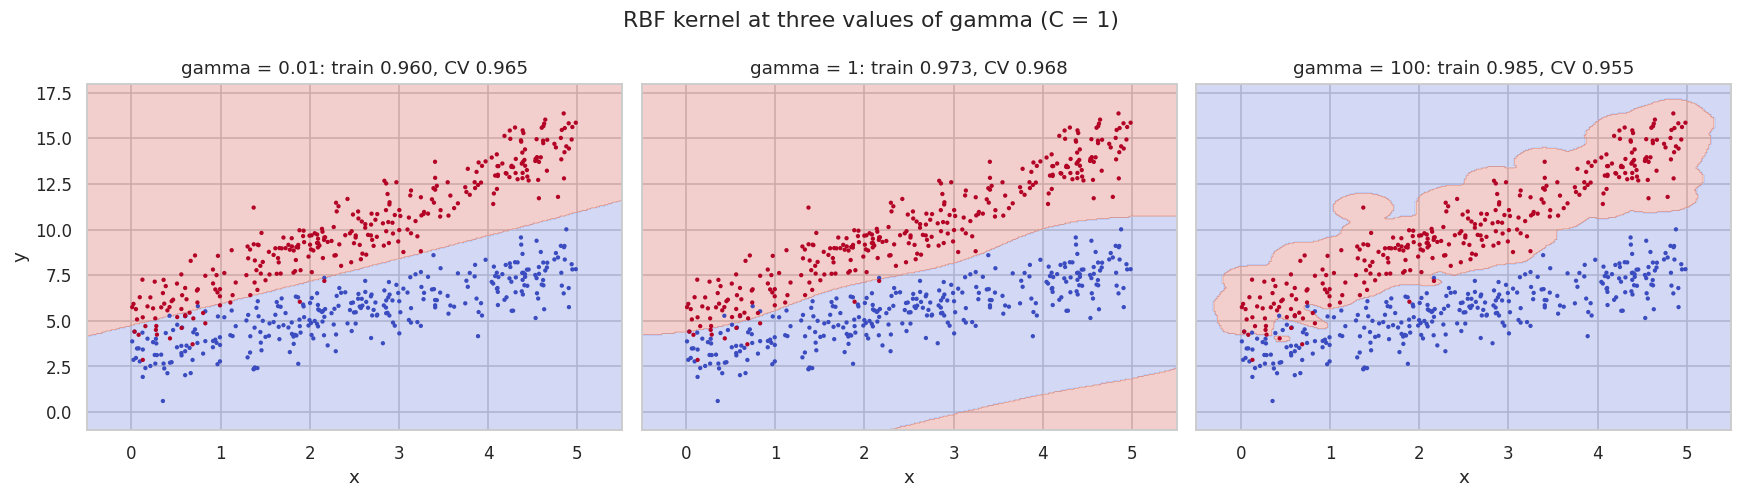

          support vectors  train accuracy  CV accuracy
gamma                                                 
0.0100                284          0.9600       0.9650
1.0000                 86          0.9733       0.9683
100.0000              487          0.9850       0.9550

(c) same folds, C = 1
    linear               CV accuracy 0.9717 +/- 0.0085   folds [0.975 0.967 0.958 0.983 0.975]
    rbf, gamma='scale'   CV accuracy 0.9683 +/- 0.0097   folds [0.958 0.967 0.958 0.983 0.975]


In [25]:
_svm_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

# (a) C on the linear kernel
print("(a) linear kernel")
_c_rows = []
for C in (0.001, 1, 1000):
    pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C, random_state=SEED)).fit(_X_two, _y_two)
    svc = pipe.named_steps["svc"]
    _c_rows.append({"C": C, "support vectors": int(svc.n_support_.sum()),
                    "margin 2/|w| (scaled)": 2 / np.linalg.norm(svc.coef_),
                    "train accuracy": pipe.score(_X_two, _y_two),
                    "CV accuracy": cross_val_score(pipe, _X_two, _y_two, cv=_svm_cv).mean()})
print(pd.DataFrame(_c_rows).set_index("C").round(4).to_string())

# (b) gamma on the RBF kernel
print("\n(b) RBF kernel, C = 1")
_g_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
_gx, _gy = np.meshgrid(np.linspace(-0.5, 5.5, 300), np.linspace(-1, 18, 300))
for ax, gamma in zip(axes, (0.01, 1, 100)):
    pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma=gamma, random_state=SEED))
    cv_acc = cross_val_score(pipe, _X_two, _y_two, cv=_svm_cv).mean()
    pipe.fit(_X_two, _y_two)
    _g_rows.append({"gamma": gamma, "support vectors": int(pipe.named_steps["svc"].n_support_.sum()),
                    "train accuracy": pipe.score(_X_two, _y_two), "CV accuracy": cv_acc})
    zz = pipe.predict(np.column_stack([_gx.ravel(), _gy.ravel()])).reshape(_gx.shape)
    ax.contourf(_gx, _gy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(_X_two[:, 0], _X_two[:, 1], c=_y_two, cmap="coolwarm", s=8, edgecolor="none")
    ax.set_title(f"gamma = {gamma}: train {pipe.score(_X_two, _y_two):.3f}, CV {cv_acc:.3f}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
fig.suptitle("RBF kernel at three values of gamma (C = 1)")
fig.tight_layout()
plt.show()
print(pd.DataFrame(_g_rows).set_index("gamma").round(4).to_string())

# (c) linear against RBF at default settings
print("\n(c) same folds, C = 1")
for name, model in (("linear", SVC(kernel="linear", C=1.0, random_state=SEED)),
                    ("rbf, gamma='scale'", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))):
    folds = cross_val_score(make_pipeline(StandardScaler(), model), _X_two, _y_two, cv=_svm_cv)
    print(f"    {name:20} CV accuracy {folds.mean():.4f} +/- {folds.std():.4f}   folds {folds.round(3)}")

**Your answer:**

**(a)** Лінійне ядро на двох «смугах»:

| C | опорних векторів | ширина зазору 2/‖w‖ | train | CV |
|---|---|---|---|---|
| 0,001 | 600 | 4,94 | 0,8350 | 0,8317 |
| 1 | 74 | 0,41 | 0,9717 | 0,9717 |
| 1000 | 46 | 0,22 | 0,9733 | 0,9717 |

Мале C означає **недонавчання**: штраф за порушення зазору настільки малий, що зазор стає величезним (4,94 у масштабованих одиницях), усі 600 точок лежать усередині нього і є опорними, а межа визначається масою точок і погано розділяє класи (CV 0,8317). Велике C веде в бік **перенавчання**: порушення дуже дорогі, зазор звужується до 0,22, щоб пристосуватися до окремих точок біля межі, і межа спирається лише на 46 точок, тобто стає чутливішою до конкретних спостережень. Для лінійного ядра у двох вимірах гнучкість обмежена, тому перехресна точність при C = 1000 не падає (0,9717), але навчальна вже трохи вища.

**(b)** RBF при C = 1: γ = 0,01 дає 284 опорні вектори, навчальну точність 0,9600 і перехресну 0,9650, межа майже пряма. γ = 1 дає 86 опорних векторів, 0,9733 і 0,9683, межа плавно вигнута і близька до лінійної, хоча в порожньому правому нижньому куті з'являється хибна «червона» область, де даних немає. γ = 100 дає 487 опорних векторів, 0,9850 і 0,9550: межа щільно обгортає червоні точки нерівним островом з відростками, а все поза даними стає синім. Ядро exp(−γ‖x − x′‖²) означає, що вплив однієї навчальної точки згасає з відстанню на масштабі приблизно 1/√γ (у масштабованих одиницях 10, 1 і 0,1). Мале γ дає кожній точці вплив на весь простір, тому межа надто гладка і близька до лінійної (бік недонавчання). Велике γ дає кожній точці вплив лише на найближчу околицю, і саме ця крайність **запам'ятовує** дані: найвища навчальна і найнижча перехресна точність.

**(c)** На тих самих фолдах лінійне ядро дає 0,9717 ± 0,0085, RBF з `gamma='scale'` дає 0,9683 ± 0,0097, а в чотирьох фолдах із п'яти точності однакові. Різниця −0,003 менша за розкид між фолдами, тож RBF не має переваги. Справжня межа між двома зашумленими лінійними смугами є прямою, і помилки виникають через перекриття шуму, яке є невідворотним, а не через форму межі; додаткова гнучкість може підлаштуватися лише під шум. Загальний принцип: обирати найпростіше ядро, достатнє для структури задачі. Гнучкість понад потрібну додає дисперсію, гіперпараметри для налаштування і артефакти на кшталт хибної області при γ = 1, не зменшуючи зміщення. Перехід до RBF виправданий лише тоді, коли перехресна перевірка показує реальний виграш, більший за розкид між фолдами.

## 10. Task 9 — Choosing the number of clusters

Applied.

*see Practice 3 §13.3 and §14.5*

In [26]:
def cluster_selection(X, k_values):
    """Score k-means and a Gaussian mixture across several k.

    For each k in `k_values` (all >= 2), compute four numbers:
        'inertia'      KMeans(n_clusters=k, n_init=10, random_state=SEED).inertia_
        'silhouette'   silhouette_score of that KMeans labelling
        'bic'          GaussianMixture(n_components=k, covariance_type='full',
                       random_state=SEED).bic(X)
        'aic'          the same model's aic(X)

    Return a DataFrame indexed by k with those four columns, in that order.
    """
    rows = {}
    for k in k_values:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=SEED).fit(X)
        rows[k] = {
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "bic": gmm.bic(X),
            "aic": gmm.aic(X),
        }
    result = pd.DataFrame.from_dict(rows, orient="index")[["inertia", "silhouette", "bic", "aic"]]
    result.index.name = "k"
    return result

In [27]:
_blob_rng = np.random.default_rng(SEED)
_centres = np.array([[-4.0, -2.0], [0.0, 3.5], [4.0, -1.0], [6.5, 4.0]])
_X_blobs = np.vstack([_blob_rng.multivariate_normal(c, np.eye(2), 75) for c in _centres])

_scores = cluster_selection(_X_blobs, range(2, 8))

assert list(_scores.columns) == ["inertia", "silhouette", "bic", "aic"]
assert len(_scores) == 6

# Inertia falls monotonically: more clusters always fit the points more tightly.
assert np.all(np.diff(_scores["inertia"].values) < 0), \
    "inertia must decrease as k increases, which is why it cannot be minimised to choose k"

# On four well-separated round blobs, every criterion should find four.
assert _scores["silhouette"].idxmax() == 4, \
    f"silhouette chose {_scores['silhouette'].idxmax()}, expected 4 on four round blobs"
assert _scores["bic"].idxmin() == 4, f"BIC chose {_scores['bic'].idxmin()}, expected 4"

print(_scores.round(3).to_string())
print(f"\nsilhouette -> {_scores['silhouette'].idxmax()},  "
      f"BIC -> {_scores['bic'].idxmin()},  AIC -> {_scores['aic'].idxmin()}")
print("Task 9 passed.")

     inertia  silhouette        bic        aic
k                                             
2 3,260.9450      0.4940 2,842.1730 2,801.4310
3 1,694.5460      0.5650 2,716.3210 2,653.3560
4   553.3610      0.6970 2,603.9330 2,518.7460
5   495.1520      0.5980 2,631.5810 2,524.1720
6   443.6920      0.5070 2,664.4790 2,534.8470
7   387.6340      0.4260 2,691.7670 2,539.9120

silhouette -> 4,  BIC -> 4,  AIC -> 4
Task 9 passed.


### Question 7 — clustering choices

**(a)** Plot inertia against k. Explain why it cannot be minimised to
choose k, and what the "elbow" is supposed to represent. Then state
honestly how confident you are reading the elbow on your own plot.

**(b)** Now build the harder data below — three tilted components, two of
which overlap — and run `cluster_selection` on it. **Silhouette and BIC
will disagree.** Report both answers, say which is right, and explain
*why* the silhouette gives the answer it does in terms of what it
measures.

**(c)** Re-run k-means on that data with `n_init=1` and ten different
`random_state` values, recording the inertia each time. Report the spread.
What is `n_init` for, and what does `init='k-means++'` change?

**(d)** Fit a GMM to that data with each `covariance_type` in
`('full', 'tied', 'diag', 'spherical')` and report the adjusted Rand
index against the true labels. Which assumption is each making, and which
one reproduces k-means' behaviour?

In [28]:
# The harder data for parts (b), (c) and (d). Do not modify this cell.
_hard_rng = np.random.default_rng(SEED)
X_hard = np.vstack([
    _hard_rng.multivariate_normal([0.0, 0.0], [[2.0, 2.0], [2.0, 5.0]], 300),
    _hard_rng.multivariate_normal([4.0, 4.0], [[7.0, -2.0], [-2.0, 3.0]], 300),
    _hard_rng.multivariate_normal([6.0, 6.5], [[3.0, 1.5], [1.5, 2.0]], 300),
])
y_hard = np.repeat([0, 1, 2], 300)

print("X_hard", X_hard.shape, " true components: 3")

X_hard (900, 2)  true components: 3


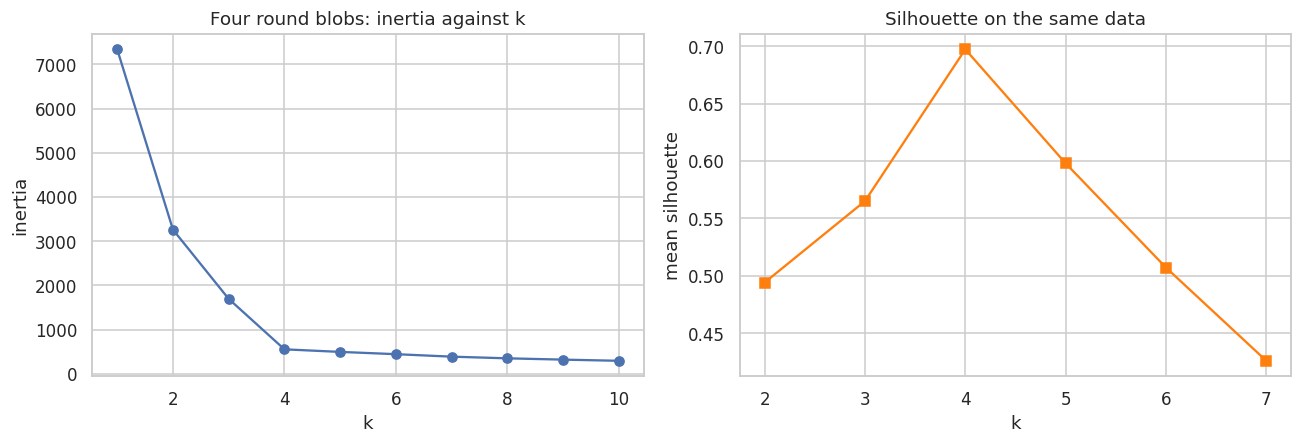

inertia: {1: 7339.9, 2: 3260.9, 3: 1694.5, 4: 553.4, 5: 495.2, 6: 443.7, 7: 387.6, 8: 349.7, 9: 320.5, 10: 293.9}
relative drop from k-1 to k: {2: 0.556, 3: 0.48, 4: 0.673, 5: 0.105, 6: 0.104, 7: 0.126, 8: 0.098, 9: 0.083, 10: 0.083}



(b) X_hard
     inertia  silhouette        bic        aic
k                                             
2 7,175.0020      0.5160 8,512.4190 8,459.5920
3 4,690.2510      0.4230 8,410.6690 8,329.0280
4 3,470.1580      0.4280 8,451.9990 8,341.5440
5 2,822.5210      0.4040 8,490.5460 8,351.2760
6 2,355.3400      0.3660 8,526.4190 8,358.3360
7 1,994.2770      0.3680 8,559.2670 8,362.3680
silhouette -> 2,  BIC -> 3,  AIC -> 3   (truth: 3)
ARI against the true labels: k-means k=2 0.4463, k-means k=3 0.4606, GMM full k=3 0.6407
ARI of k-means k=2 against 'component 0' vs 'components 1 and 2 merged': 0.7261


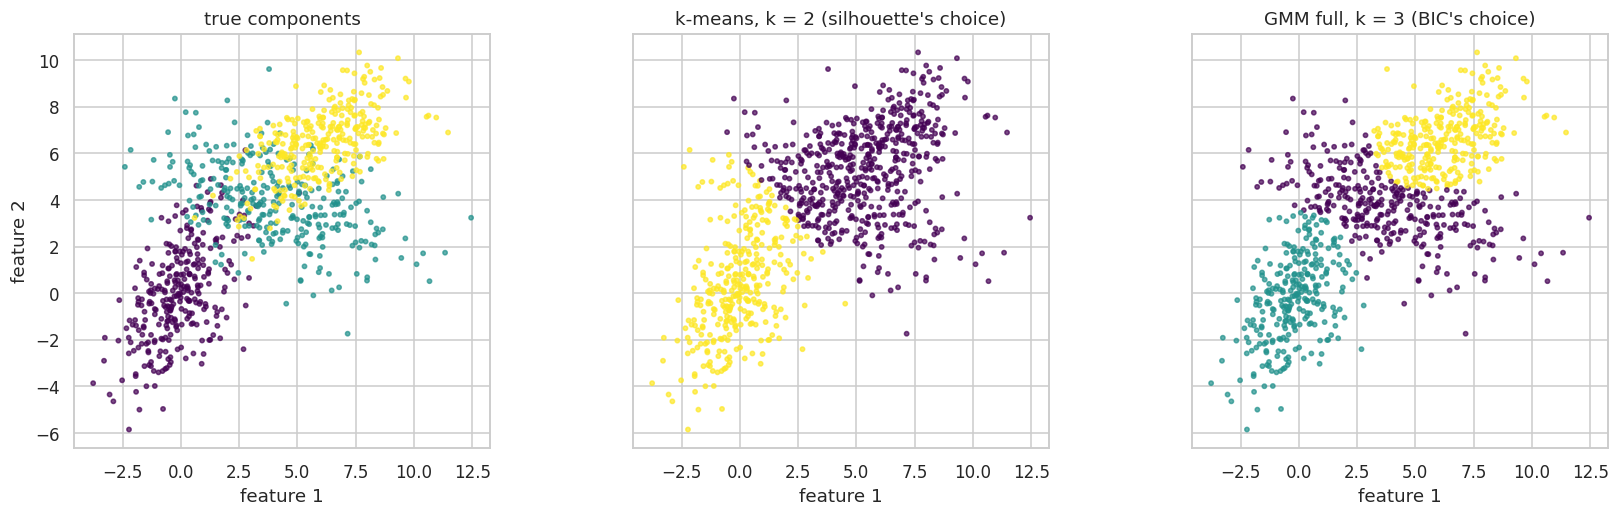


(c) k-means, k = 3, n_init = 1, random_state 0..9
    init=random     [4691.4 4691.9 4691.9 4691.9 4691.9 4690.3 4691.9 4690.3 4691.9 4690.2]  spread 1.7 (0.04% of the best)
    init=k-means++  [4691.9 4690.3 4690.3 4691.9 4691.9 4691.9 4691.9 4692.7 4691.9 4690.3]  spread 2.5 (0.05% of the best)
    n_init = 10, init='random': 4690.3

(d) GMM with 3 components, ARI against the true labels
    full       ARI 0.6407   parameters 17   BIC   8410.7   agreement with k-means k=3 (ARI) 0.6098
    tied       ARI 0.4493   parameters 11   BIC   8561.7   agreement with k-means k=3 (ARI) 0.7661
    diag       ARI 0.4362   parameters 14   BIC   8544.7   agreement with k-means k=3 (ARI) 0.8991
    spherical  ARI 0.4527   parameters 11   BIC   8576.1   agreement with k-means k=3 (ARI) 0.9025
    k-means    ARI 0.4606


In [29]:
# (a) inertia on the four blobs, from k = 1
_inertia_all = {k: KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(_X_blobs).inertia_ for k in range(1, 11)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(list(_inertia_all), list(_inertia_all.values()), marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("Four round blobs: inertia against k")
axes[1].plot(_scores.index, _scores["silhouette"], marker="s", color="tab:orange")
axes[1].set_xlabel("k")
axes[1].set_ylabel("mean silhouette")
axes[1].set_title("Silhouette on the same data")
fig.tight_layout()
plt.show()
_vals = np.array(list(_inertia_all.values()))
print("inertia:", {k: round(v, 1) for k, v in _inertia_all.items()})
print("relative drop from k-1 to k:", {k: round(float(1 - _vals[k - 1] / _vals[k - 2]), 3) for k in range(2, 11)})

# (b) the harder data
_hard_scores = cluster_selection(X_hard, range(2, 8))
print("\n(b) X_hard")
print(_hard_scores.round(3).to_string())
print(f"silhouette -> {_hard_scores['silhouette'].idxmax()},  BIC -> {_hard_scores['bic'].idxmin()},  "
      f"AIC -> {_hard_scores['aic'].idxmin()}   (truth: 3)")
_km2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X_hard)
_km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_hard)
_gm3 = GaussianMixture(n_components=3, covariance_type="full", random_state=SEED).fit(X_hard)
print(f"ARI against the true labels: k-means k=2 {adjusted_rand_score(y_hard, _km2.labels_):.4f}, "
      f"k-means k=3 {adjusted_rand_score(y_hard, _km3.labels_):.4f}, GMM full k=3 {adjusted_rand_score(y_hard, _gm3.predict(X_hard)):.4f}")
_merged = np.where(y_hard == 0, 0, 1)
print(f"ARI of k-means k=2 against 'component 0' vs 'components 1 and 2 merged': "
      f"{adjusted_rand_score(_merged, _km2.labels_):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, (title, labels) in zip(axes, (("true components", y_hard),
                                      ("k-means, k = 2 (silhouette's choice)", _km2.labels_),
                                      ("GMM full, k = 3 (BIC's choice)", _gm3.predict(X_hard)))):
    ax.scatter(X_hard[:, 0], X_hard[:, 1], c=labels, cmap="viridis", s=8, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("feature 1")
    ax.set_aspect("equal")
axes[0].set_ylabel("feature 2")
fig.tight_layout()
plt.show()

# (c) one start, ten seeds
print("\n(c) k-means, k = 3, n_init = 1, random_state 0..9")
for init in ("random", "k-means++"):
    inert = np.array([KMeans(n_clusters=3, n_init=1, init=init, random_state=s).fit(X_hard).inertia_
                      for s in range(10)])
    print(f"    init={init:10} {inert.round(1)}  spread {inert.max() - inert.min():.1f} "
          f"({(inert.max() - inert.min()) / inert.min():.2%} of the best)")
print(f"    n_init = 10, init='random': {KMeans(n_clusters=3, n_init=10, init='random', random_state=0).fit(X_hard).inertia_:.1f}")

# (d) covariance types
print("\n(d) GMM with 3 components, ARI against the true labels")
for ct in ("full", "tied", "diag", "spherical"):
    gm = GaussianMixture(n_components=3, covariance_type=ct, random_state=SEED).fit(X_hard)
    lab = gm.predict(X_hard)
    print(f"    {ct:10} ARI {adjusted_rand_score(y_hard, lab):.4f}   parameters {int(gm._n_parameters()):2}   "
          f"BIC {gm.bic(X_hard):8.1f}   agreement with k-means k=3 (ARI) {adjusted_rand_score(_km3.labels_, lab):.4f}")
print(f"    k-means    ARI {adjusted_rand_score(y_hard, _km3.labels_):.4f}")

**Your answer:**

**(a)** Інерція на чотирьох кулястих групах при k = 1…10 дорівнює 7339,9; 3260,9; 1694,5; 553,4; 495,2; 443,7; 387,6; 349,7; 320,5; 293,9 і спадає монотонно. Мінімізувати її для вибору k неможливо, бо додатковий центр завжди зменшує відстань до найближчого центру, і при k = n кожна точка є власним кластером з нульовою інерцією, тож мінімум завжди припадає на найбільше k. «Лікоть» є тим k, після якого новий кластер перестає давати великий виграш, тобто межею між розділенням справжніх груп (великий виграш) і дробленням однієї групи на частини (малий виграш). Відносні зниження до k = 4 становлять 55,6 %, 48,0 % і 67,3 %, а далі лише 10,5 %, 10,4 %, 12,6 % і менше, тож лікоть на k = 4 тут однозначний і збігається з максимумом силуету (0,697). На цьому графіку я впевнений у відповіді, але лише тому, що групи добре розділені й однакові. Лікоть читається на око, і на реальних даних з групами, що перекриваються, крива згинається поступово; тоді я не покладався б на нього без інших критеріїв.

**(b)** На `X_hard` силует максимальний при k = 2 (0,516 проти 0,423 при k = 3), а BIC мінімальний при k = 3 (8410,7 проти 8512,4 при 2 і 8452,0 при 4); AIC теж обирає 3. Правильна відповідь 3, тож правий BIC. Силует вимірює, наскільки кожна точка ближча до свого кластера, ніж до найближчого чужого, тобто винагороджує компактні, добре розділені групи. Друга і третя компоненти (центри (4; 4) і (6; 6,5)) сильно перекриваються, тому їхнє злиття справді дає компактніший поділ: k-means з k = 2 збігається з поділом «компонента 0 проти злитих 1 і 2» з ARI 0,7261. Силует коректно відповідає на своє запитання, але воно інше, ніж запитання про кількість породжувальних компонент. BIC оцінює правдоподібність даних за моделлю суміші з поправкою на кількість параметрів, і на це запитання відповідь 3. Узгодженість зі справжніми мітками (ARI) становить 0,4463 для k-means з k = 2, 0,4606 для k-means з k = 3 і 0,6407 для повної GMM з k = 3.

**(c)** З `n_init=1` і `random_state` від 0 до 9 при k = 3 інерція для `init='random'` лежить у межах 4690,2–4691,9 (розкид 1,7, тобто 0,04 % від найкращої), для `init='k-means++'` у межах 4690,3–4692,7 (розкид 2,5, 0,05 %). На цих даних k-means практично з будь-якого старту приходить до одного з кількох майже рівноцінних локальних мінімумів, бо структура проста, тоді як на чотирьох групах Practice 3 §13.4 окремі випадкові старти застрягали в поганих мінімумах. `n_init` задає кількість незалежних стартів, з яких зберігається результат із найменшою інерцією, і цим захищає від невдалого старту (`n_init=10` з випадковою ініціалізацією дав 4690,3). `init='k-means++'` обирає початкові центри рознесеними: кожен наступний центр вибирається з імовірністю, пропорційною квадрату відстані до найближчого вже обраного. Це робить погані старти малоймовірними, але не гарантує глобального мінімуму, і тут один із його запусків (4692,7) виявився найгіршим із двадцяти.

**(d)** GMM з трьома компонентами дала такі ARI: `full` 0,6407 (17 параметрів, BIC 8410,7), `tied` 0,4493 (11, 8561,7), `diag` 0,4362 (14, 8544,7), `spherical` 0,4527 (11, 8576,1); для порівняння k-means 0,4606. `full` дозволяє кожній компоненті власну коваріаційну матрицю, тобто будь-яку форму й нахил еліпса, і саме так згенеровано дані, тому вона найкраща за ARI і за BIC. `tied` вимагає однієї спільної матриці для всіх компонент, тобто однакової форми й орієнтації, що хибно, бо одна з компонент нахилена в протилежний бік. `diag` дозволяє різні дисперсії вздовж осей, але без кореляції, тобто лише еліпси, вирівняні за осями, і не може відтворити нахил. `spherical` дозволяє кожній компоненті лише одну дисперсію в усіх напрямках, тобто круглі кластери, і саме вона відтворює поведінку k-means: її мітки збігаються з мітками k-means з ARI 0,9025 (найвища узгодженість серед чотирьох типів), а точність щодо істини майже та сама (0,4527 проти 0,4606). k-means можна розглядати як граничний випадок сферичної суміші з однаковими дисперсіями і жорстким призначенням точок.

## 11. Task 10 — Open-ended: an end-to-end regression study

No assert. Marked on the written analysis and on the discipline of the
procedure.

**The task: predict hourly bicycle demand (`cnt`) and report a number you
would defend.**

`bike_sharing_hourly.csv` is documented in `practice/datasets/README.md`.
Work through the following, in this order, and write up what you find.

1. **Feature preparation.** Decide what to do with each column. `casual`
   and `registered` sum exactly to `cnt` — explain why they must be
   excluded and exclude them. Encode the integer-coded categories
   properly (Practice 3 §10.2) and justify each choice in one line.

2. **Split once.** Hold out a test set and do not look at it again until
   step 6. State your `test_size` and why.

3. **A baseline.** Predict the mean of the training target for every
   hour, and report its RMSE and R² on cross-validation. Every later
   number is read against this.

4. **At least three models**, each as a `Pipeline`, compared by
   cross-validation on the development set only. Report mean and standard
   deviation across folds, not a single number. Use at least one linear
   and one non-linear model.

5. **Tune the best one** with `GridSearchCV` over the pipeline. State the
   grid and how many fits it implies.

6. **Open the test set once.** Report RMSE, MAE and R². Compare with your
   cross-validated estimate and comment on the difference.

7. **Diagnose.** Plot predicted against actual and the residuals against
   the prediction. Does the model predict impossible values? Do the
   residuals fan out? What does that say about which hours it fails on?

8. **A decision.** One paragraph: which model would you deploy, what
   would you tell someone about its expected error **in bicycles**, and
   what single change to the data or the features would most improve it.

A good answer treats step 6 as irreversible and says so. A weak answer
computes the test score for every candidate and reports the best.

In [30]:
# Step 1. Feature preparation, recording every decision
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate

study = bikes.copy()
decisions = []

study = study.drop(columns=["casual", "registered"])
decisions.append("casual, registered: casual + registered == cnt on every row, so they ARE the target. "
                 "Excluded (target leakage).")
study = study.drop(columns=["instant", "dteday"])
decisions.append("instant: a row number. dteday: a string whose information is already in yr, mnth, "
                 "weekday and holiday. Both excluded.")
study = study.drop(columns=["atemp"])
decisions.append("atemp: correlates 0.99 with temp and holds a constant, wrong value for all of "
                 "2012-08-17 (Lesson 2 homework). Excluded; temp kept.")
study.loc[study["hum"] == 0, "hum"] = np.nan
decisions.append("hum: the 22 values of exactly 0 (all on 2011-03-10, in rain) are a sensor failure. "
                 "Set to missing and imputed inside the pipeline with the training median.")

categorical = ["season", "mnth", "hr", "weekday", "weathersit"]
binary = ["yr", "holiday", "workingday"]
numeric = ["temp", "hum", "windspeed"]
decisions.append("hr: 24 nominal levels with two peaks, one-hot (Practice 3 section 10.2).")
decisions.append("season, mnth, weekday: integer codes of nominal (cyclic) categories, one-hot.")
decisions.append("weathersit: ordered, but the gaps between levels are not equal, one-hot; "
                 "handle_unknown='ignore' because level 4 occurs in only 3 hours.")
decisions.append("yr, holiday, workingday: already 0/1, passed through.")
decisions.append("temp, hum, windspeed: numeric, standardised for the linear and kNN models.")
decisions.append("Trees and forests get the integer codes as they are: a tree splits on thresholds "
                 "and can isolate any level, so one-hot only slows it down (Lesson 2 homework, Question 4c).")

y_all = study.pop("cnt").values.astype(float)
X_all = study[categorical + binary + numeric]
print("features:", list(X_all.columns), "  X", X_all.shape, "  y", y_all.shape)
print("missing values now:", X_all.isna().sum()[X_all.isna().sum() > 0].to_dict())
print()
for i, decision in enumerate(decisions, 1):
    print(f"{i:2}. {decision}")

def onehot_preprocessor():
    return ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("binary", "passthrough", binary),
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ])

def tree_preprocessor():
    return ColumnTransformer([
        ("codes", "passthrough", categorical + binary),
        ("numeric", SimpleImputer(strategy="median"), numeric),
    ])

features: ['season', 'mnth', 'hr', 'weekday', 'weathersit', 'yr', 'holiday', 'workingday', 'temp', 'hum', 'windspeed']   X (17379, 11)   y (17379,)
missing values now: {'hum': 22}

 1. casual, registered: casual + registered == cnt on every row, so they ARE the target. Excluded (target leakage).
 2. instant: a row number. dteday: a string whose information is already in yr, mnth, weekday and holiday. Both excluded.
 3. atemp: correlates 0.99 with temp and holds a constant, wrong value for all of 2012-08-17 (Lesson 2 homework). Excluded; temp kept.
 4. hum: the 22 values of exactly 0 (all on 2011-03-10, in rain) are a sensor failure. Set to missing and imputed inside the pipeline with the training median.
 5. hr: 24 nominal levels with two peaks, one-hot (Practice 3 section 10.2).
 6. season, mnth, weekday: integer codes of nominal (cyclic) categories, one-hot.
 7. weathersit: ordered, but the gaps between levels are not equal, one-hot; handle_unknown='ignore' because level 4 occurs in 

In [31]:
# Step 2. Split once. Nothing below reads X_test or y_test until step 6.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
print(f"development set {X_dev.shape}, test set {X_test.shape}")
print(f"cnt in dev: mean {y_dev.mean():.1f}, sd {y_dev.std():.1f};  in test: mean {y_test.mean():.1f}, sd {y_test.std():.1f}")

development set (13903, 11), test set (3476, 11)
cnt in dev: mean 188.4, sd 180.8;  in test: mean 193.6, sd 183.8


In [32]:
# Step 3. The baseline: the training mean, for every hour
study_cv = KFold(5, shuffle=True, random_state=SEED)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def cv_summary(model, name):
    res = cross_validate(model, X_dev, y_dev, cv=study_cv, scoring=scoring)
    return {"model": name,
            "rmse": -res["test_rmse"].mean(), "rmse_sd": res["test_rmse"].std(),
            "mae": -res["test_mae"].mean(),
            "r2": res["test_r2"].mean(), "r2_sd": res["test_r2"].std(),
            "fit_s": res["fit_time"].mean()}

baseline_row = cv_summary(DummyRegressor(strategy="mean"), "baseline: training mean")
print(pd.DataFrame([baseline_row]).set_index("model").round(4).to_string())

                            rmse  rmse_sd      mae      r2  r2_sd  fit_s
model                                                                   
baseline: training mean 180.7710   1.5182 142.0010 -0.0006 0.0005 0.0009


In [33]:
# Step 4. Candidate models, each a Pipeline, compared by 5-fold CV on the development set
candidates = {
    "linear regression (one-hot)": make_pipeline(onehot_preprocessor(), LinearRegression()),
    "linear regression on log(1 + cnt)": TransformedTargetRegressor(
        regressor=make_pipeline(onehot_preprocessor(), LinearRegression()),
        func=np.log1p, inverse_func=np.expm1),
    "kNN, k = 10 (one-hot, scaled)": make_pipeline(onehot_preprocessor(), KNeighborsRegressor(n_neighbors=10)),
    "decision tree, min_samples_leaf = 5": make_pipeline(tree_preprocessor(),
                                                         DecisionTreeRegressor(min_samples_leaf=5, random_state=SEED)),
    "random forest, 200 trees": make_pipeline(tree_preprocessor(),
                                              RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)),
}
comparison_rows = [baseline_row] + [cv_summary(model, name) for name, model in candidates.items()]
comparison = pd.DataFrame(comparison_rows).set_index("model")
print(comparison.round(4).to_string())

# Does the plain linear model predict impossible values? (development data only)
from sklearn.model_selection import cross_val_predict
_lin_dev_pred = cross_val_predict(candidates["linear regression (one-hot)"], X_dev, y_dev, cv=study_cv)
print(f"\nlinear regression, out-of-fold: {np.mean(_lin_dev_pred < 0):.2%} of predictions are negative "
      f"(minimum {_lin_dev_pred.min():.0f} bicycles)")

                                        rmse  rmse_sd      mae      r2  r2_sd  fit_s
model                                                                               
baseline: training mean             180.7710   1.5182 142.0010 -0.0006 0.0005 0.0009
linear regression (one-hot)         101.8721   1.9496  75.4256  0.6821 0.0128 0.0226
linear regression on log(1 + cnt)    97.8409   3.1861  63.2085  0.7067 0.0161 0.0229
kNN, k = 10 (one-hot, scaled)       111.4825   2.1872  79.4255  0.6193 0.0140 0.0123
decision tree, min_samples_leaf = 5  55.2925   2.7083  32.8022  0.9061 0.0098 0.0314
random forest, 200 trees             44.3489   1.9134  26.3638  0.9396 0.0057 2.9112

linear regression, out-of-fold: 10.41% of predictions are negative (minimum -206 bicycles)


In [34]:
# Step 5. Tune the best candidate, still on the development set only
forest_grid = {
    "randomforestregressor__max_features": [0.5, 1.0],
    "randomforestregressor__min_samples_leaf": [1, 2, 4],
}
n_combinations = int(np.prod([len(v) for v in forest_grid.values()]))
print(f"grid: {forest_grid}")
print(f"{n_combinations} combinations x 5 folds = {n_combinations * 5} fits, plus 1 refit on the whole development set")

forest_search = GridSearchCV(
    make_pipeline(tree_preprocessor(), RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)),
    forest_grid, cv=study_cv, scoring="neg_root_mean_squared_error", refit=True,
)
forest_search.fit(X_dev, y_dev)
_fs = pd.DataFrame(forest_search.cv_results_)
_fs_table = pd.DataFrame({
    "max_features": _fs["param_randomforestregressor__max_features"],
    "min_samples_leaf": _fs["param_randomforestregressor__min_samples_leaf"],
    "cv_rmse": -_fs["mean_test_score"], "cv_rmse_sd": _fs["std_test_score"],
}).sort_values("cv_rmse")
print(_fs_table.round(3).to_string(index=False))
print(f"\nbest: {forest_search.best_params_}, CV RMSE {-forest_search.best_score_:.3f}")

best_model = forest_search.best_estimator_
_best_cv = cross_validate(best_model, X_dev, y_dev, cv=study_cv, scoring=scoring)
cv_estimate = {"rmse": -_best_cv["test_rmse"].mean(), "mae": -_best_cv["test_mae"].mean(), "r2": _best_cv["test_r2"].mean()}
print("cross-validated estimate of the selected model:", {k: round(float(v), 4) for k, v in cv_estimate.items()})

# A harder check, still without the test set: folds that are contiguous blocks of time
_order = np.argsort(bikes.loc[X_dev.index, "instant"].values)
_blocked = cross_validate(best_model, X_dev.iloc[_order], y_dev[_order], cv=KFold(5, shuffle=False), scoring=scoring)
print(f"same model, folds = five consecutive blocks of time: RMSE {-_blocked['test_rmse'].mean():.2f} "
      f"(+/- {_blocked['test_rmse'].std():.2f}), R^2 {_blocked['test_r2'].mean():.4f}")
print("\nThis is the last decision. The test set is opened once, below.")

grid: {'randomforestregressor__max_features': [0.5, 1.0], 'randomforestregressor__min_samples_leaf': [1, 2, 4]}
6 combinations x 5 folds = 30 fits, plus 1 refit on the whole development set


 max_features  min_samples_leaf  cv_rmse  cv_rmse_sd
       1.0000                 1  44.3490      1.9130
       1.0000                 2  44.5200      1.9240
       0.5000                 1  45.8050      1.1340
       1.0000                 4  46.0780      1.9740
       0.5000                 2  47.2520      1.3850
       0.5000                 4  50.6720      1.4530

best: {'randomforestregressor__max_features': 1.0, 'randomforestregressor__min_samples_leaf': 1}, CV RMSE 44.349


cross-validated estimate of the selected model: {'rmse': 44.3489, 'mae': 26.3638, 'r2': 0.9396}


same model, folds = five consecutive blocks of time: RMSE 66.68 (+/- 7.49), R^2 0.7962

This is the last decision. The test set is opened once, below.


In [35]:
# Step 6. Open the test set, once
test_pred = best_model.predict(X_test)
test_metrics = regression_metrics(y_test, test_pred)
baseline_test = regression_metrics(y_test, np.full_like(y_test, y_dev.mean()))
print(f"{'':28} {'RMSE':>8} {'MAE':>8} {'R2':>8}")
print(f"{'cross-validated estimate':28} {cv_estimate['rmse']:8.2f} {cv_estimate['mae']:8.2f} {cv_estimate['r2']:8.4f}")
print(f"{'test set (opened once)':28} {test_metrics['rmse']:8.2f} {test_metrics['mae']:8.2f} {test_metrics['r2']:8.4f}")
print(f"{'baseline on the test set':28} {baseline_test['rmse']:8.2f} {baseline_test['mae']:8.2f} {baseline_test['r2']:8.4f}")
print(f"\ndifference test - CV: RMSE {test_metrics['rmse'] - cv_estimate['rmse']:+.2f}, "
      f"R^2 {test_metrics['r2'] - cv_estimate['r2']:+.4f}; fold-to-fold sd of the CV RMSE was "
      f"{_best_cv['test_rmse'].std():.2f}")

                                 RMSE      MAE       R2
cross-validated estimate        44.35    26.36   0.9396
test set (opened once)          41.32    25.45   0.9495
baseline on the test set       183.87   143.03  -0.0008

difference test - CV: RMSE -3.03, R^2 +0.0098; fold-to-fold sd of the CV RMSE was 1.91


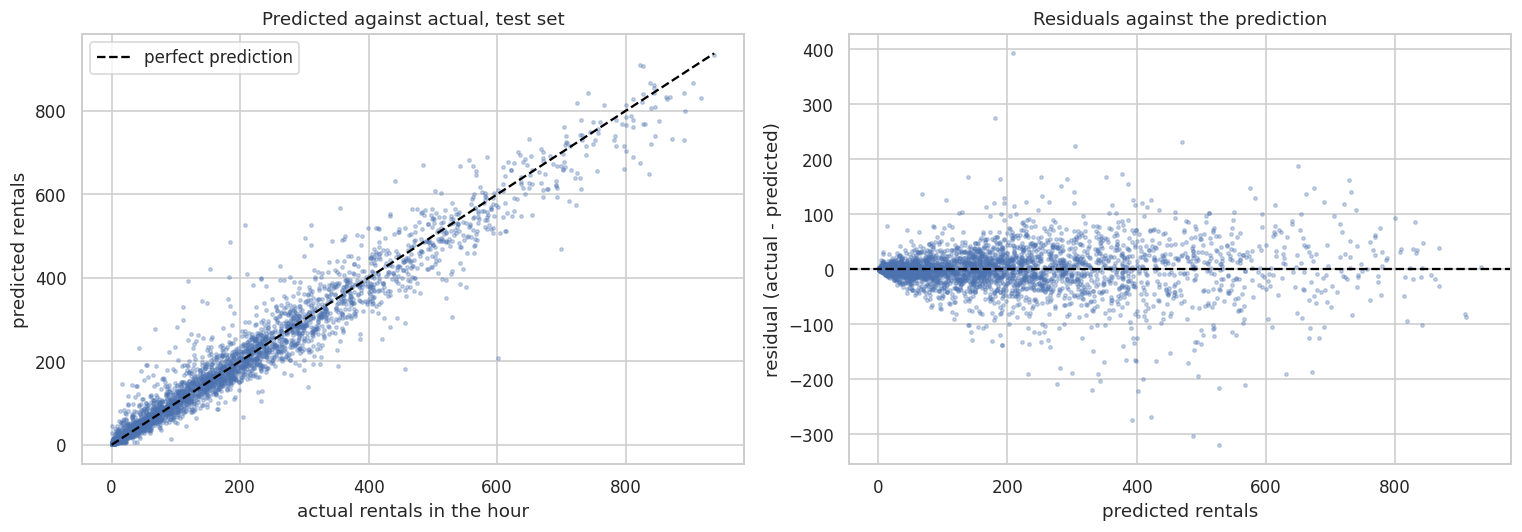

predictions below zero: 0;  smallest prediction 1.3;  largest 932.9 (largest actual 938)

residual spread by size of the prediction:
             hours    mean      sd  mean_abs
(0, 50]        886 -0.6000  9.2000    5.9000
(50, 150]      841 -1.7000 26.9000   19.1000
(150, 300]     951  1.3000 45.4000   31.3000
(300, 500]     532 -3.1000 63.4000   45.7000
(500, 1000]    266  1.6000 66.0000   49.3000

mean absolute error by hour of day and type of day (test set):
hr                   0       1       2      3      4      5       6       7       8       9       10      11      12      13      14      15      16      17      18      19      20      21      22      23
non-working day 16.2000 17.1000 13.3000 7.3000 3.6000 4.2000  7.6000 20.8000 19.2000 35.8000 37.6000 35.1000 42.7000 40.4000 37.5000 46.7000 54.8000 53.2000 41.1000 38.5000 29.2000 32.7000 21.0000 21.0000
working day     10.4000  5.6000  4.3000 2.1000 1.8000 4.9000 12.4000 33.4000 52.2000 28.8000 16.4000 22.7000 22.3000 23.300

In [36]:
# Step 7. Diagnose
residuals = y_test - test_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, test_pred, s=5, alpha=0.3)
_lim = max(y_test.max(), test_pred.max())
axes[0].plot([0, _lim], [0, _lim], color="black", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("actual rentals in the hour")
axes[0].set_ylabel("predicted rentals")
axes[0].set_title("Predicted against actual, test set")
axes[0].legend()
axes[1].scatter(test_pred, residuals, s=5, alpha=0.3)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("predicted rentals")
axes[1].set_ylabel("residual (actual - predicted)")
axes[1].set_title("Residuals against the prediction")
fig.tight_layout()
plt.show()

print(f"predictions below zero: {(test_pred < 0).sum()};  smallest prediction {test_pred.min():.1f};  "
      f"largest {test_pred.max():.1f} (largest actual {y_test.max():.0f})")
_bins = pd.cut(test_pred, [0, 50, 150, 300, 500, 1000])
print("\nresidual spread by size of the prediction:")
print(pd.DataFrame({"pred": test_pred, "res": residuals}).groupby(_bins, observed=True)["res"]
      .agg(hours="size", mean="mean", sd="std", mean_abs=lambda r: r.abs().mean()).round(1).to_string())

_diag = X_test.assign(actual=y_test, predicted=test_pred, abs_error=np.abs(residuals))
print("\nmean absolute error by hour of day and type of day (test set):")
_by_hour = _diag.groupby(["hr", "workingday"])["abs_error"].mean().unstack().round(1)
_by_hour.columns = ["non-working day", "working day"]
print(_by_hour.T.to_string())
print("\nworst ten hours:")
_worst10 = _diag.sort_values("abs_error", ascending=False).head(10)
_worst10 = _worst10.assign(date=bikes.loc[_worst10.index, "dteday"].values,
                           actual=_worst10["actual"].astype(int),
                           predicted=_worst10["predicted"].round().astype(int))
print(_worst10[["date", "hr", "workingday", "holiday", "weathersit", "actual", "predicted"]].to_string())

In [37]:
# Feature importances of the selected forest (a description of what it used, not causes)
_forest = best_model.named_steps["randomforestregressor"]
_importances = pd.Series(_forest.feature_importances_, index=categorical + binary + numeric).sort_values(ascending=False)
print(_importances.round(4).to_string())

hr           0.6099
temp         0.1356
yr           0.0802
workingday   0.0573
hum          0.0299
season       0.0232
weathersit   0.0188
mnth         0.0165
weekday      0.0146
windspeed    0.0111
holiday      0.0029


**Your write-up:**

**1. Підготовка ознак.** `casual` і `registered` виключено, бо їхня сума дорівнює `cnt` у кожному рядку, тобто це сама ціль (витік). `instant` є номером рядка, а `dteday` містить інформацію, яка вже є в `yr`, `mnth`, `weekday`, `holiday`, тому обидва виключено. `atemp` виключено, бо він корелює з `temp` на рівні 0,99 і містить сталі хибні значення за весь день 2012-08-17. 22 нульові значення `hum` (усі 2011-03-10, під час дощу) є збоєм датчика, їх замінено пропусками і заповнено медіаною навчальної частини всередині конвеєра, тобто окремо в кожному фолді. `hr` (24 рівні з двома піками), `season`, `mnth` і `weekday` (коди циклічних номінальних категорій) та `weathersit` (порядок є, але відстані між рівнями нерівні) закодовано one-hot з `handle_unknown='ignore'`, бо рівень 4 погоди трапляється лише в трьох годинах. `yr`, `holiday`, `workingday` вже є 0/1 і передаються без змін. `temp`, `hum`, `windspeed` для лінійних моделей і kNN стандартизовано. Деревам і лісу передано цілі коди як є: дерево ділить за порогами і може виділити будь-який рівень, тож one-hot лише сповільнює його. Разом 11 вихідних ознак.

**2. Одне розбиття.** `test_size=0.2`, `random_state=SEED`: 13 903 години для розробки і 3476 для тесту. Двадцяти відсотків достатньо, щоб тестова RMSE була точною (на п'ятій частині розробки RMSE коливається між фолдами лише на 2 велосипеди), а 80 % залишаються для навчання і перехресної перевірки. Випадкове розбиття означає, що ми оцінюємо помилку для годин того самого періоду 2011–2012 років, а не для прогнозу майбутнього; це обмеження я окремо перевірив у кроці 5 без тестових даних. Після цього рядка тестова частина не використовувалася до кроку 6.

**3. Базова модель.** Прогноз середнім навчальної частини дає на перехресній перевірці RMSE 180,77 ± 1,52, MAE 142,00 і R² −0,0006 (трохи від'ємний, бо середнє навчального фолду не збігається із середнім валідаційного). Усі подальші числа читаються відносно цього.

**4. Моделі.** П'ятикратна перехресна перевірка на розробці (середнє ± sd по фолдах): лінійна регресія з one-hot має RMSE 101,87 ± 1,95 і R² 0,682 ± 0,013; лінійна регресія на log(1 + cnt) 97,84 ± 3,19 і 0,707 ± 0,016; kNN з k = 10 111,48 ± 2,19 і 0,619 ± 0,014; дерево з `min_samples_leaf=5` 55,29 ± 2,71 і 0,906 ± 0,010; випадковий ліс із 200 дерев 44,35 ± 1,91 і 0,940 ± 0,006. Лінійна модель дає 10,41 % від'ємних прогнозів поза фолдом (мінімум −206 велосипедів) і не має взаємодій: ефект години додається однаково до робочих і неробочих днів, хоча профілі цих днів зовсім різні. Дерева враховують такі взаємодії автоматично. Перевага лісу над одним деревом (11 велосипедів RMSE) приблизно в п'ять разів перевищує розкид між фолдами, тобто є реальною.

**5. Налаштування.** Для лісу я перебрав `max_features` ∈ {0,5; 1,0} × `min_samples_leaf` ∈ {1, 2, 4}, тобто 6 комбінацій × 5 фолдів = 30 підгонок і одна фінальна на всій розробці. Найкращою виявилася комбінація `max_features=1.0`, `min_samples_leaf=1` з CV RMSE 44,35, тобто стандартні налаштування; наступна поступається лише на 0,17 при розкиді 1,9, тож налаштування підтвердило вихідні параметри, а не покращило їх. Додатково, все ще без тесту, я перевірив ту саму модель на фолдах, що є п'ятьма послідовними відрізками часу: RMSE 66,68 ± 7,49 і R² 0,796. Модель значно гірше прогнозує період, якого не бачила, ніж окремі години всередині знайомого періоду.

**6. Тест, один раз.** Тестова частина відкрита один раз, і жодне рішення після цього не змінювалося. Результат: RMSE 41,32, MAE 25,45, R² 0,9495 проти перехресної оцінки 44,35, 26,36 і 0,9396; базова модель на тесті дає RMSE 183,87. Тест виявився на 3,03 RMSE кращим, що відповідає приблизно 1,6 розкиду між фолдами і пояснюється випадковістю саме цієї вибірки з 3476 годин. Ознак того, що процедура підлаштувалася під розробку, немає, а чесна оцінка помилки лежить у діапазоні 41–44.

**7. Діагностика.** Від'ємних прогнозів немає (мінімум 1,3), бо ліс усереднює спостережені значення і не виходить за межі навчальних цілей; найбільший прогноз 932,9 при найбільшому фактичному значенні 938. Залишки розходяться віялом: стандартне відхилення 9,2 для прогнозів до 50, 26,9 для 50–150, 45,4 для 150–300, 63,4 для 300–500 і 66,0 понад 500, тобто помилка зростає з рівнем попиту, як і належить лічильним даним, при цьому середній залишок у кожній групі близький до нуля (від −3,1 до +1,6), систематичного зсуву немає. Найбільша середня абсолютна помилка припадає на години пік робочих днів (8:00 52,2; 17:00 52,6; 18:00 52,9) і на післяобідні години неробочих днів (15–17 год, 46,7–54,8), найменша на ніч (1,8–4,3). Найгірші десять годин є переважно особливими днями, яких ознаки не описують. День після Дня подяки 2011-11-25, позначений у даних як робочий, дав о 17:00 і 18:00 лише 184 і 153 поїздки проти прогнозу 487 і 422, так само 2012-11-23 о 18:00 (208 проти 527), а сам День подяки 2012-11-22 о 16:00 дав 182 проти 403. День незалежності 2011-07-04 о 21:00 дав 457 поїздок проти 181, імовірно через вечірній феєрверк. 2011-08-23 о 15:00 зафіксовано 601 поїздку проти 208; цього дня стався землетрус у Вірджинії, після якого у Вашингтоні евакуювали офісні будівлі, і люди роз'їжджалися раніше. Ще дві години з цієї десятки припали на дощ (2012-08-10 о 8:00: 119 проти 394; 2012-05-14 о 16:00: 111 проти 331). Отже, моделі бракує не гнучкості, а відомостей про особливі дні та погоду в конкретну годину.

**8. Рішення.** Я розгорнув би випадковий ліс із 200 дерев зі стандартними параметрами, обраний процедурою до відкриття тесту. Для годин того самого періоду очікувана помилка становить RMSE близько 41–44 і MAE близько 25–26 велосипедів за годину, але вона сильно залежить від рівня попиту: вночі в середньому кілька велосипедів, у години пік близько 50 (середня абсолютна помилка). Якщо модель має прогнозувати новий період, слід орієнтуватися на RMSE близько 67 і R² близько 0,80, як показала перевірка на послідовних відрізках часу. Найбільше покращення дала б одна зміна ознак: додати попит попередньої години і тієї самої години попереднього дня. Ці значення відомі до початку прогнозованої години, тож це не витік (на відміну від `casual` і `registered` тієї ж години); у другій домашній роботі зареєстровані поїздки попередньої години корелювали з поточним попитом на рівні 0,80. Такі ознаки відображають саме те, чого бракує календарним ознакам: незвичні дні, раптову зміну погоди, загальний рівень попиту в конкретний період. Оцінювати таку модель треба лише на хронологічному розбитті.

## 12. Before you submit

- Runtime → **Restart and run all**. Every cell executes in order, every
  assert passes.
- Every written question has an answer referring to numbers you produced,
  and names which direction is underfitting and which is overfitting
  where the question asks for it.
- Task 10 has a written decision, not only code.